In [31]:
!pip install -q pandas numpy scikit-learn openpyxl tensorflow rdkit

In [32]:
import os
import random
import warnings

import numpy as np
import pandas as pd

from rdkit import Chem
from rdkit.Chem import (
    AllChem,
    Descriptors,
    Crippen,
    Lipinski,
    rdMolDescriptors
)
from rdkit.Chem.Scaffolds import MurckoScaffold

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")


# ============================================================
# RANDOM SEED
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# ============================================================
# FILE
# ============================================================

FILE = "tox21_cleaned_final.csv"


# ============================================================
# COLUMNS
# ============================================================

SMILES_COLUMN = "canonical_smiles"

TARGETS = [
    "NR-AR",
    "NR-AR-LBD",
    "NR-AhR",
    "NR-Aromatase",
    "NR-ER",
    "NR-ER-LBD",
    "NR-PPAR-gamma",
    "SR-ARE",
    "SR-ATAD5",
    "SR-HSE",
    "SR-MMP",
    "SR-p53"
]


# ============================================================
# SPLIT
# ============================================================

TRAIN_FRACTION = 0.70
VALIDATION_FRACTION = 0.15
TEST_FRACTION = 0.15


# ============================================================
# MODEL
# ============================================================

N_BITS = 2048
N_DESCRIPTORS = 9
N_FEATURES = N_BITS + N_DESCRIPTORS
N_TASKS = len(TARGETS)


print("TensorFlow version:", tf.__version__)
print("Number of tasks:", N_TASKS)
print("Number of features:", N_FEATURES)
from sklearn.metrics import roc_curve, precision_recall_curve


TensorFlow version: 2.21.0
Number of tasks: 12
Number of features: 2057


In [33]:
# ============================================================
# GLOBAL TYPOGRAPHY: TIMES NEW ROMAN, 12 PT
# ============================================================
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 12,
    "axes.titlesize": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 12,
    "savefig.dpi": 300,
})

# Make pandas tables easier to read in notebook outputs.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

print("Plot typography set to Times New Roman, 12 pt.")

Plot typography set to Times New Roman, 12 pt.


In [34]:
# ============================================================
# LOAD DATASET (ROBUST GOOGLE COLAB UPLOAD)
# ============================================================

import os
import pandas as pd
from google.colab import files

EXPECTED_FILE = "/content/tox21_cleaned_final.csv"

# If the expected file is not present, let the user upload the cleaned CSV.
if not os.path.exists(EXPECTED_FILE):
    print("The file 'tox21_cleaned_final.csv' was not found in /content.")
    print("Upload your cleaned Tox21 CSV file now.")
    uploaded = files.upload()

    csv_names = [
        name for name in uploaded.keys()
        if name.lower().endswith(".csv")
    ]

    if not csv_names:
        raise FileNotFoundError(
            "No CSV file was uploaded. Upload your cleaned Tox21 dataset."
        )

    chosen_file = csv_names[0]
    uploaded_path = os.path.join("/content", chosen_file)

    if os.path.abspath(uploaded_path) != os.path.abspath(EXPECTED_FILE):
        os.replace(uploaded_path, EXPECTED_FILE)

df = pd.read_csv(EXPECTED_FILE)

print("=" * 70)
print("TOX21 DATASET")
print("=" * 70)
print("Loaded file:", EXPECTED_FILE)
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("\nColumns:")
print(df.columns.tolist())

# ============================================================
# CHECK REQUIRED COLUMNS
# ============================================================

required_columns = [
    "mol_id",
    "inchikey",
    "canonical_smiles"
] + TARGETS

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        "The uploaded CSV is missing required columns: "
        f"{missing_columns}. Please upload the cleaned Tox21 CSV "
        "that contains mol_id, inchikey, canonical_smiles, and all 12 endpoints."
    )

print("\nAll required columns are present.")

# ============================================================
# DATA TYPES
# ============================================================

print("\nEndpoint data types:")
print(df[TARGETS].dtypes)

# ============================================================
# LABEL AUDIT
# ============================================================

audit = []

for endpoint in TARGETS:
    tested = int(df[endpoint].notna().sum())
    missing = int(df[endpoint].isna().sum())
    active = int((df[endpoint] == 1).sum())
    inactive = int((df[endpoint] == 0).sum())
    active_rate = active / tested if tested > 0 else np.nan
    missing_fraction = missing / len(df) if len(df) else np.nan

    audit.append({
        "Endpoint": endpoint,
        "Total": len(df),
        "Tested": tested,
        "Missing": missing,
        "Missing_Fraction": missing_fraction,
        "Active": active,
        "Inactive": inactive,
        "Active_Rate": active_rate
    })

audit_df = pd.DataFrame(audit)

print("\n" + "=" * 70)
print("LABEL AUDIT")
print("=" * 70)
print(audit_df.to_string(
    index=False,
    formatters={
        "Missing_Fraction": "{:.4f}".format,
        "Active_Rate": "{:.4f}".format
    }
))

audit_df.to_csv("label_audit.csv", index=False)

print("\nDuplicate InChIKeys:")
print(df["inchikey"].duplicated().sum())

print("\nMissing canonical SMILES:")
print(df[SMILES_COLUMN].isna().sum())

TOX21 DATASET
Loaded file: /content/tox21_cleaned_final.csv
Rows: 7592
Columns: 19

Columns:
['mol_id', 'smiles', 'canonical_smiles', 'inchikey', 'valid_smiles', 'structure_changed', 'cleaning_error', 'NR-AR', 'NR-AR-LBD', 'NR-AhR', 'NR-Aromatase', 'NR-ER', 'NR-ER-LBD', 'NR-PPAR-gamma', 'SR-ARE', 'SR-ATAD5', 'SR-HSE', 'SR-MMP', 'SR-p53']

All required columns are present.

Endpoint data types:
NR-AR            float64
NR-AR-LBD        float64
NR-AhR           float64
NR-Aromatase     float64
NR-ER            float64
NR-ER-LBD        float64
NR-PPAR-gamma    float64
SR-ARE           float64
SR-ATAD5         float64
SR-HSE           float64
SR-MMP           float64
SR-p53           float64
dtype: object

LABEL AUDIT
     Endpoint  Total  Tested  Missing Missing_Fraction  Active  Inactive Active_Rate
        NR-AR   7592    7023      569           0.0749     300      6723      0.0427
    NR-AR-LBD   7592    6551     1041           0.1371     230      6321      0.0351
       NR-AhR   7592 

In [35]:
# ============================================================
# MOLECULE VALIDATION
# ============================================================

def valid_molecule(smiles):

    if pd.isna(smiles):
        return False

    try:
        mol = Chem.MolFromSmiles(str(smiles))

        return mol is not None

    except Exception:
        return False


df["valid_molecule"] = df[
    SMILES_COLUMN
].apply(valid_molecule)


invalid_count = (
    (~df["valid_molecule"]).sum()
)

print(
    "Invalid/missing molecules:",
    invalid_count
)


# ============================================================
# REMOVE INVALID MOLECULES
# ============================================================

df = df[
    df["valid_molecule"]
].copy()

df.drop(
    columns=["valid_molecule"],
    inplace=True
)

df.reset_index(
    drop=True,
    inplace=True
)


print(
    "Dataset after molecule validation:",
    df.shape
)


# ============================================================
# SCAFFOLD FUNCTION
# ============================================================

def get_scaffold(smiles):

    mol = Chem.MolFromSmiles(
        str(smiles)
    )

    scaffold = (
        MurckoScaffold.GetScaffoldForMol(mol)
    )

    return Chem.MolToSmiles(
        scaffold,
        canonical=True
    )


# ============================================================
# CREATE SCAFFOLDS
# ============================================================

df["scaffold"] = df[
    SMILES_COLUMN
].apply(get_scaffold)


print(
    "\nNumber of unique scaffolds:",
    df["scaffold"].nunique()
)


print("\nLargest scaffold groups:")

print(
    df["scaffold"]
    .value_counts()
    .head(10)
)

Invalid/missing molecules: 9
Dataset after molecule validation: (7583, 19)

Number of unique scaffolds: 2346

Largest scaffold groups:
scaffold
                         1698
c1ccccc1                 1454
c1ccncc1                   88
c1ccc(Cc2ccccc2)cc1        81
c1ccc2ccccc2c1             65
C1CCCCC1                   63
c1ccc(Oc2ccccc2)cc1        44
c1ccc(-c2ccccc2)cc1        39
C1=CCCCC1                  38
O=C(c1ccccc1)c1ccccc1      36
Name: count, dtype: int64


In [36]:
# ============================================================
# CELL 5 — BALANCED STRATIFIED SCAFFOLD SPLIT
# 70% TRAIN / 15% VALIDATION / 15% TEST
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

TRAIN_FRAC = 0.70
VAL_FRAC   = 0.15
TEST_FRAC  = 0.15

assert abs(TRAIN_FRAC + VAL_FRAC + TEST_FRAC - 1.0) < 1e-6

rng = np.random.default_rng(SEED)

# ------------------------------------------------------------
# 1. Calculate overall statistics for each endpoint
# ------------------------------------------------------------

overall_stats = {}

for target in TARGETS:

    observed = df[target].dropna()

    active = int((observed == 1).sum())
    inactive = int((observed == 0).sum())
    tested = active + inactive

    if tested > 0:
        active_rate = active / tested
    else:
        active_rate = np.nan

    overall_stats[target] = {
        "tested": tested,
        "active": active,
        "inactive": inactive,
        "active_rate": active_rate
    }

print("Overall endpoint statistics:")
print("-" * 80)

for target in TARGETS:
    s = overall_stats[target]

    print(
        f"{target:15s} | "
        f"Tested={s['tested']:5d} | "
        f"Active={s['active']:5d} | "
        f"Inactive={s['inactive']:5d} | "
        f"Active rate={s['active_rate']:.4f}"
    )


# ------------------------------------------------------------
# 2. Create scaffold groups
# ------------------------------------------------------------

scaffold_groups = df.groupby("scaffold", sort=False)

scaffold_records = []

for scaffold, group in scaffold_groups:

    record = {
        "scaffold": scaffold,
        "n_molecules": len(group)
    }

    # Store tested/active counts for every endpoint
    for target in TARGETS:

        values = group[target].dropna()

        record[f"{target}_tested"] = len(values)
        record[f"{target}_active"] = int((values == 1).sum())

    scaffold_records.append(record)

scaffold_df = pd.DataFrame(scaffold_records)

print("\nNumber of unique scaffolds:", len(scaffold_df))


# ------------------------------------------------------------
# 3. Shuffle scaffolds
#
# Large scaffolds are placed first because assigning them first
# gives the balancing algorithm more control over the split.
# ------------------------------------------------------------

scaffold_df = scaffold_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

scaffold_df["size"] = scaffold_df["n_molecules"]

# Sort large scaffolds first
scaffold_df = scaffold_df.sort_values(
    by="size",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 4. Target molecule counts
# ------------------------------------------------------------

total_molecules = len(df)

target_sizes = {
    "train": total_molecules * TRAIN_FRAC,
    "val": total_molecules * VAL_FRAC,
    "test": total_molecules * TEST_FRAC
}

print("\nTarget split sizes:")
print(f"Train      : {target_sizes['train']:.1f}")
print(f"Validation : {target_sizes['val']:.1f}")
print(f"Test       : {target_sizes['test']:.1f}")


# ------------------------------------------------------------
# 5. Target active counts for each endpoint
#
# For example, if the whole dataset has 20% active NR-AR,
# then the algorithm tries to put approximately:
#
# Train:      70% of NR-AR actives
# Validation: 15%
# Test:       15%
#
# The same is done independently for all 12 endpoints.
# ------------------------------------------------------------

target_active_counts = {
    "train": {},
    "val": {},
    "test": {}
}

for target in TARGETS:

    total_active = overall_stats[target]["active"]

    target_active_counts["train"][target] = total_active * TRAIN_FRAC
    target_active_counts["val"][target]   = total_active * VAL_FRAC
    target_active_counts["test"][target]  = total_active * TEST_FRAC


# ------------------------------------------------------------
# 6. Initialize split containers
# ------------------------------------------------------------

splits = {
    "train": [],
    "val": [],
    "test": []
}

split_molecule_counts = {
    "train": 0,
    "val": 0,
    "test": 0
}

split_tested_counts = {
    "train": {target: 0 for target in TARGETS},
    "val":   {target: 0 for target in TARGETS},
    "test":  {target: 0 for target in TARGETS}
}

split_active_counts = {
    "train": {target: 0 for target in TARGETS},
    "val":   {target: 0 for target in TARGETS},
    "test":  {target: 0 for target in TARGETS}
}


# ------------------------------------------------------------
# 7. Function to calculate how good a split would be
# ------------------------------------------------------------

def calculate_split_score(
    scaffold_row,
    split_name
):

    # Current size
    current_size = split_molecule_counts[split_name]

    # New size after adding scaffold
    new_size = current_size + scaffold_row["n_molecules"]

    # --------------------------------------------------------
    # Size error
    # --------------------------------------------------------

    target_size = target_sizes[split_name]

    size_error = abs(new_size - target_size) / total_molecules


    # --------------------------------------------------------
    # Endpoint activity-rate error
    # --------------------------------------------------------

    rate_error = 0.0

    for target in TARGETS:

        current_tested = split_tested_counts[
            split_name
        ][target]

        current_active = split_active_counts[
            split_name
        ][target]

        scaffold_tested = scaffold_row[
            f"{target}_tested"
        ]

        scaffold_active = scaffold_row[
            f"{target}_active"
        ]

        new_tested = current_tested + scaffold_tested
        new_active = current_active + scaffold_active

        # If this endpoint has no observations in this split yet,
        # don't calculate an artificial rate error.
        if new_tested == 0:
            continue

        new_rate = new_active / new_tested

        overall_rate = overall_stats[
            target
        ]["active_rate"]

        if not np.isnan(overall_rate):

            # Difference between split and overall activity rate
            difference = abs(new_rate - overall_rate)

            # Weight endpoints equally
            rate_error += difference


    # --------------------------------------------------------
    # Combine size + activity-rate errors
    # --------------------------------------------------------

    # Activity balance is more important than exact molecule count.
    score = (
        0.35 * size_error +
        0.65 * rate_error
    )

    return score


# ------------------------------------------------------------
# 8. Assign every scaffold to one split
# ------------------------------------------------------------

split_names = ["train", "val", "test"]

for _, scaffold_row in scaffold_df.iterrows():

    scores = {}

    for split_name in split_names:

        scores[split_name] = calculate_split_score(
            scaffold_row,
            split_name
        )

    # --------------------------------------------------------
    # Avoid filling train too much before validation/test
    # --------------------------------------------------------

    allowed_splits = []

    for split_name in split_names:

        current_size = split_molecule_counts[split_name]
        target_size = target_sizes[split_name]

        # Allow some flexibility because whole scaffolds
        # cannot be divided.
        if current_size <= target_size * 1.05:
            allowed_splits.append(split_name)

    if len(allowed_splits) == 0:
        allowed_splits = split_names

    # Choose the best-scoring split
    best_split = min(
        allowed_splits,
        key=lambda x: scores[x]
    )

    # --------------------------------------------------------
    # Assign scaffold
    # --------------------------------------------------------

    scaffold = scaffold_row["scaffold"]

    splits[best_split].append(scaffold)

    # --------------------------------------------------------
    # Update molecule count
    # --------------------------------------------------------

    split_molecule_counts[
        best_split
    ] += scaffold_row["n_molecules"]

    # --------------------------------------------------------
    # Update endpoint statistics
    # --------------------------------------------------------

    for target in TARGETS:

        split_tested_counts[
            best_split
        ][target] += scaffold_row[
            f"{target}_tested"
        ]

        split_active_counts[
            best_split
        ][target] += scaffold_row[
            f"{target}_active"
        ]


# ------------------------------------------------------------
# 9. Convert scaffold assignments into datasets
# ------------------------------------------------------------

train_scaffolds = set(splits["train"])
val_scaffolds   = set(splits["val"])
test_scaffolds  = set(splits["test"])

train_df = df[df["scaffold"].isin(train_scaffolds)].copy()
val_df   = df[df["scaffold"].isin(val_scaffolds)].copy()
test_df  = df[df["scaffold"].isin(test_scaffolds)].copy()


# ------------------------------------------------------------
# 10. Print split sizes
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL SPLIT SIZES")
print("=" * 80)

print(
    f"Train      : {len(train_df):5d} "
    f"({len(train_df)/len(df)*100:.2f}%)"
)

print(
    f"Validation : {len(val_df):5d} "
    f"({len(val_df)/len(df)*100:.2f}%)"
)

print(
    f"Test       : {len(test_df):5d} "
    f"({len(test_df)/len(df)*100:.2f}%)"
)


# ------------------------------------------------------------
# 11. Verify NO scaffold leakage
# ------------------------------------------------------------

train_df = df[df["scaffold"].isin(train_scaffolds)].copy()

validation_df = df[
    df["scaffold"].isin(val_scaffolds)
].copy()

test_df = df[
    df["scaffold"].isin(test_scaffolds)
].copy()

# Use the scaffold-set variables defined immediately above.
train_val_overlap = train_scaffolds.intersection(val_scaffolds)
train_test_overlap = train_scaffolds.intersection(test_scaffolds)
val_test_overlap = val_scaffolds.intersection(test_scaffolds)

print("\n" + "=" * 80)
print("SCAFFOLD LEAKAGE CHECK")
print("=" * 80)

print("Train ∩ Validation :", len(train_val_overlap))
print("Train ∩ Test       :", len(train_test_overlap))
print("Validation ∩ Test  :", len(val_test_overlap))

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print("\nPASS: No scaffold appears in more than one split.")


# ------------------------------------------------------------
# 12. Detailed endpoint balance check
# ------------------------------------------------------------

balance_rows = []

print("\n" + "=" * 120)
print("ENDPOINT ACTIVITY BALANCE")
print("=" * 120)

for target in TARGETS:

    overall_rate = overall_stats[target]["active_rate"]

    row = {
        "endpoint": target,
        "overall_active_rate": overall_rate
    }

    print(f"\n{target}")
    print("-" * 80)

    for split_name, split_data in [
        ("train", train_df),
        ("validation", val_df),
        ("test", test_df)
    ]:

        observed = split_data[target].dropna()

        tested = len(observed)
        active = int((observed == 1).sum())
        inactive = int((observed == 0).sum())

        if tested > 0:
            active_rate = active / tested
        else:
            active_rate = np.nan

        difference = (
            abs(active_rate - overall_rate)
            if tested > 0
            else np.nan
        )

        print(
            f"{split_name:12s} | "
            f"Tested={tested:5d} | "
            f"Active={active:5d} | "
            f"Inactive={inactive:5d} | "
            f"Active rate={active_rate:.4f} | "
            f"Difference={difference:.4f}"
        )

        row[f"{split_name}_tested"] = tested
        row[f"{split_name}_active"] = active
        row[f"{split_name}_inactive"] = inactive
        row[f"{split_name}_active_rate"] = active_rate
        row[f"{split_name}_rate_difference"] = difference

    balance_rows.append(row)


# ------------------------------------------------------------
# 13. Save balance report
# ------------------------------------------------------------

balance_df = pd.DataFrame(balance_rows)

balance_df.to_csv(
    "stratified_scaffold_split_balance.csv",
    index=False
)

print("\nBalance report saved as:")
print("stratified_scaffold_split_balance.csv")


# ------------------------------------------------------------
# 14. Calculate average activity-rate deviation
# ------------------------------------------------------------

rate_difference_columns = [
    "train_rate_difference",
    "validation_rate_difference",
    "test_rate_difference"
]

mean_difference = balance_df[
    rate_difference_columns
].mean().mean()

max_difference = balance_df[
    rate_difference_columns
].max().max()

print("\n" + "=" * 80)
print("BALANCE SUMMARY")
print("=" * 80)

print(
    f"Mean absolute active-rate difference: "
    f"{mean_difference:.4f}"
)

print(
    f"Maximum absolute active-rate difference: "
    f"{max_difference:.4f}"
)


# ------------------------------------------------------------
# 15. Save datasets
# ------------------------------------------------------------

train_df.to_csv(
    "train.csv",
    index=False
)

val_df.to_csv(
    "validation.csv",
    index=False
)

test_df.to_csv(
    "test.csv",
    index=False
)

print("\nSaved:")
print("  train.csv")
print("  validation.csv")
print("  test.csv")


# ------------------------------------------------------------
# 16. Final confirmation
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CELL 5 COMPLETE")
print("=" * 80)

print("✓ Approximately 70% / 15% / 15% split")
print("✓ Scaffold-aware split")
print("✓ No scaffold leakage")
print("✓ Activity rates balanced across all 12 endpoints as far as possible")
print("✓ Missing labels remain missing")
print("✓ Balance report saved")

Overall endpoint statistics:
--------------------------------------------------------------------------------
NR-AR           | Tested= 7015 | Active=  299 | Inactive= 6716 | Active rate=0.0426
NR-AR-LBD       | Tested= 6543 | Active=  230 | Inactive= 6313 | Active rate=0.0352
NR-AhR          | Tested= 6333 | Active=  750 | Inactive= 5583 | Active rate=0.1184
NR-Aromatase    | Tested= 5623 | Active=  283 | Inactive= 5340 | Active rate=0.0503
NR-ER           | Tested= 5991 | Active=  765 | Inactive= 5226 | Active rate=0.1277
NR-ER-LBD       | Tested= 6738 | Active=  336 | Inactive= 6402 | Active rate=0.0499
NR-PPAR-gamma   | Tested= 6249 | Active=  175 | Inactive= 6074 | Active rate=0.0280
SR-ARE          | Tested= 5646 | Active=  898 | Inactive= 4748 | Active rate=0.1591
SR-ATAD5        | Tested= 6844 | Active=  256 | Inactive= 6588 | Active rate=0.0374
SR-HSE          | Tested= 6263 | Active=  348 | Inactive= 5915 | Active rate=0.0556
SR-MMP          | Tested= 5626 | Active=  891 | In

In [37]:
# ============================================================
# BALANCE AUDIT
# ============================================================

def split_audit(data, split_name):

    rows = []

    for endpoint in TARGETS:

        tested = data[
            endpoint
        ].notna().sum()

        missing = data[
            endpoint
        ].isna().sum()

        active = (
            data[endpoint] == 1
        ).sum()

        inactive = (
            data[endpoint] == 0
        ).sum()

        active_rate = (
            active / tested
            if tested > 0
            else np.nan
        )

        rows.append({

            "Split": split_name,

            "Endpoint": endpoint,

            "Compounds": len(data),

            "Tested": tested,

            "Missing": missing,

            "Active": active,

            "Inactive": inactive,

            "Active_Rate": active_rate
        })

    return pd.DataFrame(rows)


train_audit = split_audit(
    train_df,
    "Train"
)

validation_audit = split_audit(
    validation_df,
    "Validation"
)

test_audit = split_audit(
    test_df,
    "Test"
)


balance_audit = pd.concat(
    [
        train_audit,
        validation_audit,
        test_audit
    ],
    ignore_index=True
)


print(
    balance_audit.to_string(
        index=False,
        formatters={
            "Active_Rate":
                "{:.4f}".format
        }
    )
)


balance_audit.to_csv(
    "split_balance_audit.csv",
    index=False
)

     Split      Endpoint  Compounds  Tested  Missing  Active  Inactive Active_Rate
     Train         NR-AR       4431    4037      394     261      3776      0.0647
     Train     NR-AR-LBD       4431    3673      758     191      3482      0.0520
     Train        NR-AhR       4431    3550      881     574      2976      0.1617
     Train  NR-Aromatase       4431    3024     1407     234      2790      0.0774
     Train         NR-ER       4431    3296     1135     538      2758      0.1632
     Train     NR-ER-LBD       4431    3804      627     253      3551      0.0665
     Train NR-PPAR-gamma       4431    3412     1019     121      3291      0.0355
     Train        SR-ARE       4431    2988     1443     629      2359      0.2105
     Train      SR-ATAD5       4431    3886      545     193      3693      0.0497
     Train        SR-HSE       4431    3423     1008     230      3193      0.0672
     Train        SR-MMP       4431    3080     1351     655      2425      0.2127
    

In [38]:

# ============================================================
# IMPORTS AND RDKit CONFIGURATION
# ============================================================

import numpy as np
import pandas as pd

from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Crippen, Lipinski
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem import rdFingerprintGenerator

# Suppress repetitive RDKit warnings in notebook output.
# Invalid molecules will be handled explicitly below.
RDLogger.DisableLog("rdApp.warning")
RDLogger.DisableLog("rdApp.error")

# Modern Morgan fingerprint generator: radius=2, 2048 bits (ECFP4)
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)


# ============================================================
# PARSE AND VALIDATE MOLECULAR STRUCTURE
# ============================================================

def parse_smiles(smiles):
    if pd.isna(smiles):
        raise ValueError("Missing SMILES encountered.")

    mol = Chem.MolFromSmiles(str(smiles))

    if mol is None:
        raise ValueError(f"Invalid SMILES encountered: {smiles}")

    return mol


# ============================================================
# DESCRIPTOR FUNCTION
# ============================================================

def calculate_descriptors(smiles):
    mol = parse_smiles(smiles)

    return np.array([
        Descriptors.MolWt(mol),
        Crippen.MolLogP(mol),
        rdMolDescriptors.CalcTPSA(mol),
        Lipinski.NumHDonors(mol),
        Lipinski.NumHAcceptors(mol),
        Lipinski.NumRotatableBonds(mol),
        Lipinski.RingCount(mol),
        rdMolDescriptors.CalcFractionCSP3(mol),
        Lipinski.HeavyAtomCount(mol)
    ], dtype=np.float32)


# ============================================================
# ECFP4 FINGERPRINT FUNCTION
# ============================================================

def calculate_ecfp4(smiles):
    mol = parse_smiles(smiles)

    fingerprint = morgan_generator.GetFingerprint(mol)

    # Convert RDKit fingerprint into a NumPy array
    from rdkit import DataStructs

    arr = np.zeros(2048, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fingerprint, arr)

    return arr


# ============================================================
# GENERATE FEATURES
# ============================================================

def generate_features(data):
    ecfp = []
    descriptors = []

    invalid_rows = []

    for idx, smiles in data[SMILES_COLUMN].items():
        try:
            ecfp.append(calculate_ecfp4(smiles))
            descriptors.append(calculate_descriptors(smiles))
        except (ValueError, TypeError) as exc:
            invalid_rows.append((idx, str(exc)))

    if invalid_rows:
        examples = invalid_rows[:5]
        raise ValueError(
            f"Feature generation failed for {len(invalid_rows)} rows. "
            f"First examples: {examples}. "
            "Check the cleaned dataset before training."
        )

    return (
        np.asarray(ecfp, dtype=np.float32),
        np.asarray(descriptors, dtype=np.float32)
    )


# ============================================================
# TRAIN FEATURES
# ============================================================

X_train_ecfp, X_train_desc = generate_features(train_df)

# ============================================================
# VALIDATION FEATURES
# ============================================================

X_validation_ecfp, X_validation_desc = generate_features(
    validation_df
)

# ============================================================
# TEST FEATURES
# ============================================================

X_test_ecfp, X_test_desc = generate_features(test_df)


# ============================================================
# VERIFY OUTPUT SHAPES
# ============================================================

print("ECFP train:", X_train_ecfp.shape)
print("Descriptors train:", X_train_desc.shape)

print("ECFP validation:", X_validation_ecfp.shape)
print("Descriptors validation:", X_validation_desc.shape)

print("ECFP test:", X_test_ecfp.shape)
print("Descriptors test:", X_test_desc.shape)

assert X_train_ecfp.shape == (len(train_df), 2048)
assert X_validation_ecfp.shape == (len(validation_df), 2048)
assert X_test_ecfp.shape == (len(test_df), 2048)

assert X_train_desc.shape == (len(train_df), 9)
assert X_validation_desc.shape == (len(validation_df), 9)
assert X_test_desc.shape == (len(test_df), 9)

print("\nSUCCESS: All molecular features were generated.")

ECFP train: (4431, 2048)
Descriptors train: (4431, 9)
ECFP validation: (1698, 2048)
Descriptors validation: (1698, 9)
ECFP test: (1454, 2048)
Descriptors test: (1454, 9)

SUCCESS: All molecular features were generated.


In [39]:
# ============================================================
# STANDARDIZE PHYSICOCHEMICAL DESCRIPTORS
# ============================================================

scaler = StandardScaler()

X_train_desc = scaler.fit_transform(
    X_train_desc
)

X_validation_desc = scaler.transform(
    X_validation_desc
)

X_test_desc = scaler.transform(
    X_test_desc
)


# ============================================================
# COMBINE ECFP + DESCRIPTORS
# ============================================================

X_train = np.concatenate(
    [
        X_train_ecfp,
        X_train_desc
    ],
    axis=1
)

X_validation = np.concatenate(
    [
        X_validation_ecfp,
        X_validation_desc
    ],
    axis=1
)

X_test = np.concatenate(
    [
        X_test_ecfp,
        X_test_desc
    ],
    axis=1
)


print("=" * 70)
print("FINAL FEATURE MATRICES")
print("=" * 70)

print(
    "X_train:",
    X_train.shape
)

print(
    "X_validation:",
    X_validation.shape
)

print(
    "X_test:",
    X_test.shape
)


assert X_train.shape[1] == 2057

print(
    "\nSUCCESS: 2048 ECFP4 bits + 9 descriptors = 2057 features."
)


# ============================================================
# SAVE FEATURES
# ============================================================

np.save(
    "X_train.npy",
    X_train
)

np.save(
    "X_validation.npy",
    X_validation
)

np.save(
    "X_test.npy",
    X_test
)

FINAL FEATURE MATRICES
X_train: (4431, 2057)
X_validation: (1698, 2057)
X_test: (1454, 2057)

SUCCESS: 2048 ECFP4 bits + 9 descriptors = 2057 features.


In [40]:
# ============================================================
# LABEL + MASK CREATION
# ============================================================

def create_Y_and_mask(data):

    labels = data[
        TARGETS
    ].to_numpy(
        dtype=np.float32
    )

    # 1 = tested
    # 0 = missing

    mask = (
        ~data[TARGETS]
        .isna()
    ).to_numpy(
        dtype=np.float32
    )

    # Replace NaN only AFTER mask creation.
    #
    # These zeros are NOT considered inactive
    # because mask = 0 for those positions.

    labels = np.nan_to_num(
        labels,
        nan=0.0
    )

    return labels, mask


# ============================================================
# TRAIN
# ============================================================

Y_train, M_train = (
    create_Y_and_mask(train_df)
)


# ============================================================
# VALIDATION
# ============================================================

Y_validation, M_validation = (
    create_Y_and_mask(validation_df)
)


# ============================================================
# TEST
# ============================================================

Y_test, M_test = (
    create_Y_and_mask(test_df)
)


# ============================================================
# SHAPES
# ============================================================

print("Y_train:",
      Y_train.shape)

print("M_train:",
      M_train.shape)

print("Y_validation:",
      Y_validation.shape)

print("M_validation:",
      M_validation.shape)

print("Y_test:",
      Y_test.shape)

print("M_test:",
      M_test.shape)


# ============================================================
# CHECK
# ============================================================

assert Y_train.shape[1] == 12
assert M_train.shape[1] == 12


# ============================================================
# MISSING FRACTION
# ============================================================

print("\nTraining missing-label fraction:")

for i, endpoint in enumerate(TARGETS):

    missing_fraction = (
        1 -
        M_train[:, i].mean()
    )

    print(
        f"{endpoint:15s} "
        f"{missing_fraction:.4f}"
    )


# ============================================================
# SAVE
# ============================================================

np.save(
    "Y_train.npy",
    Y_train
)

np.save(
    "M_train.npy",
    M_train
)

np.save(
    "Y_validation.npy",
    Y_validation
)

np.save(
    "M_validation.npy",
    M_validation
)

np.save(
    "Y_test.npy",
    Y_test
)

np.save(
    "M_test.npy",
    M_test
)

Y_train: (4431, 12)
M_train: (4431, 12)
Y_validation: (1698, 12)
M_validation: (1698, 12)
Y_test: (1454, 12)
M_test: (1454, 12)

Training missing-label fraction:
NR-AR           0.0889
NR-AR-LBD       0.1711
NR-AhR          0.1988
NR-Aromatase    0.3175
NR-ER           0.2561
NR-ER-LBD       0.1415
NR-PPAR-gamma   0.2300
SR-ARE          0.3257
SR-ATAD5        0.1230
SR-HSE          0.2275
SR-MMP          0.3049
SR-p53          0.1695


In [41]:
# ============================================================
# CLASS WEIGHTS
# ============================================================

positive_weights = []

for i, endpoint in enumerate(TARGETS):

    observed = (
        M_train[:, i] == 1
    )

    y = Y_train[
        observed,
        i
    ]

    positives = np.sum(
        y == 1
    )

    negatives = np.sum(
        y == 0
    )

    if positives == 0:

        weight = 1.0

    else:

        weight = (
            negatives /
            positives
        )

    positive_weights.append(
        weight
    )


positive_weights = np.array(
    positive_weights,
    dtype=np.float32
)


print("=" * 70)
print("CLASS WEIGHTS")
print("=" * 70)

for endpoint, weight in zip(
    TARGETS,
    positive_weights
):

    print(
        f"{endpoint:15s}: {weight:.3f}"
    )

CLASS WEIGHTS
NR-AR          : 14.467
NR-AR-LBD      : 18.230
NR-AhR         : 5.185
NR-Aromatase   : 11.923
NR-ER          : 5.126
NR-ER-LBD      : 14.036
NR-PPAR-gamma  : 27.198
SR-ARE         : 3.750
SR-ATAD5       : 19.135
SR-HSE         : 13.883
SR-MMP         : 3.702
SR-p53         : 10.084


In [42]:
# ============================================================
# MASKED WEIGHTED BINARY CROSS ENTROPY
# ============================================================

def masked_weighted_bce(
    positive_weights
):

    weights = tf.constant(
        positive_weights,
        dtype=tf.float32
    )


    def loss(
        y_true_combined,
        y_pred
    ):

        # First 12 columns = labels
        y_true = (
            y_true_combined[:, :N_TASKS]
        )

        # Last 12 columns = masks
        mask = (
            y_true_combined[:, N_TASKS:]
        )


        # Numerical safety
        y_pred = tf.clip_by_value(
            y_pred,
            1e-7,
            1.0 - 1e-7
        )


        # Weighted BCE
        positive_part = (
            y_true
            * tf.math.log(y_pred)
            * weights
        )

        negative_part = (
            (1.0 - y_true)
            * tf.math.log(1.0 - y_pred)
        )


        loss_matrix = -(
            positive_part
            +
            negative_part
        )


        # ==============================================
        # MASK
        # ==============================================
        #
        # Missing label:
        #
        # mask = 0
        #
        # therefore:
        #
        # loss = loss * 0
        #
        # and its gradient contribution is zero.
        #

        loss_matrix = (
            loss_matrix * mask
        )


        # Average only over observed labels
        denominator = tf.reduce_sum(
            mask
        )

        return (
            tf.reduce_sum(
                loss_matrix
            )
            /
            tf.maximum(
                denominator,
                1.0
            )
        )


    return loss


# ============================================================
# MODEL
# ============================================================

inputs = keras.Input(
    shape=(X_train.shape[1],),
    name="molecular_features"
)


x = layers.Dense(
    512,
    activation="relu"
)(inputs)

x = layers.BatchNormalization()(x)

x = layers.Dropout(
    0.30
)(x)


x = layers.Dense(
    256,
    activation="relu"
)(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(
    0.30
)(x)


x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(
    0.20
)(x)


# ============================================================
# 12 OUTPUTS
# ============================================================

outputs = layers.Dense(
    N_TASKS,
    activation="sigmoid",
    name="toxicity_outputs"
)(x)


model = keras.Model(
    inputs=inputs,
    outputs=outputs
)


# ============================================================
# COMPILE
# ============================================================

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=masked_weighted_bce(
        positive_weights
    )
)


# ============================================================
# SUMMARY
# ============================================================

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ molecular_features (InputLayer) │ (None, 2057)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │     1,053,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ toxicity_outputs (Dense)        │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,222,540 (4.66 MB)

 Trainable params: 1,221,004 (4.66 MB)

 Non-trainable params: 1,536 (6.00 KB)

In [43]:
# ============================================================
# COMBINE LABELS + MASKS
# ============================================================

train_target = np.concatenate(
    [
        Y_train,
        M_train
    ],
    axis=1
)

validation_target = np.concatenate(
    [
        Y_validation,
        M_validation
    ],
    axis=1
)


print(
    "Training target shape:",
    train_target.shape
)

print(
    "Validation target shape:",
    validation_target.shape
)

Training target shape: (4431, 24)
Validation target shape: (1698, 24)


In [44]:
# ============================================================
# MULTI-TASK AUC CALLBACK
# ============================================================

class MacroAUC(
    keras.callbacks.Callback
):

    def __init__(
        self,
        X_validation,
        Y_validation,
        M_validation
    ):

        super().__init__()

        self.X_validation = X_validation

        self.Y_validation = Y_validation

        self.M_validation = M_validation


    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        predictions = self.model.predict(
            self.X_validation,
            verbose=0
        )


        roc_scores = []

        pr_scores = []


        for i in range(N_TASKS):

            observed = (
                self.M_validation[:, i] == 1
            )


            y_true = (
                self.Y_validation[
                    observed,
                    i
                ]
            )

            y_pred = (
                predictions[
                    observed,
                    i
                ]
            )


            # Need both classes
            if len(
                np.unique(y_true)
            ) < 2:

                continue


            roc = roc_auc_score(
                y_true,
                y_pred
            )

            pr = average_precision_score(
                y_true,
                y_pred
            )


            roc_scores.append(
                roc
            )

            pr_scores.append(
                pr
            )


        macro_roc = np.mean(
            roc_scores
        )

        macro_pr = np.mean(
            pr_scores
        )


        logs = logs or {}

        logs[
            "val_macro_roc_auc"
        ] = macro_roc

        logs[
            "val_macro_pr_auc"
        ] = macro_pr


        print(
            f" - val_macro_ROC_AUC: "
            f"{macro_roc:.4f}"
            f" - val_macro_PR_AUC: "
            f"{macro_pr:.4f}"
        )

In [45]:
# ============================================================
# CALLBACKS
# ============================================================

macro_auc_callback = MacroAUC(
    X_validation,
    Y_validation,
    M_validation
)


early_stopping = keras.callbacks.EarlyStopping(

    monitor="val_macro_roc_auc",

    mode="max",

    patience=12,

    restore_best_weights=True,

    verbose=1
)


checkpoint = keras.callbacks.ModelCheckpoint(

    "best_multitask_model.keras",

    monitor="val_macro_roc_auc",

    mode="max",

    save_best_only=True,

    verbose=1
)


# ============================================================
# TRAIN
# ============================================================

history = model.fit(

    X_train,

    train_target,

    validation_data=(
        X_validation,
        validation_target
    ),

    epochs=100,

    batch_size=64,

    callbacks=[
        macro_auc_callback,
        early_stopping,
        checkpoint
    ],

    verbose=1
)


# ============================================================
# SAVE
# ============================================================

model.save(
    "tox21_multitask_final.keras"
)


print(
    "\nTraining complete."
)

Epoch 1/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 1.3635 - val_macro_ROC_AUC: 0.6598 - val_macro_PR_AUC: 0.0932

Epoch 1: val_macro_roc_auc improved from None to 0.65982, saving model to best_multitask_model.keras

Epoch 1: finished saving model to best_multitask_model.keras
70/70 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step - loss: 1.2367 - val_loss: 0.7231 - val_macro_roc_auc: 0.6598 - val_macro_pr_auc: 0.0932
Epoch 2/100
65/70 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8567 - val_macro_ROC_AUC: 0.6969 - val_macro_PR_AUC: 0.1051

Epoch 2: val_macro_roc_auc improved from 0.65982 to 0.69689, saving model to best_multitask_model.keras

Epoch 2: finished saving model to best_multitask_model.keras
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.8336 - val_loss: 0.6330 - val_macro_roc_auc: 0.6969 - val_macro_pr_auc: 0.1051
Epoch 3/100
62/70 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6465 - val_macro_ROC_AUC: 0.6965 - val_macro_PR_AUC: 0.1141

Epoch 3: val_macro_roc_auc did not improve fro

In [46]:
# ============================================================
# MASKING UNIT TEST
# ============================================================

def simple_masked_loss(
    y_true,
    mask,
    prediction
):

    prediction = np.clip(
        prediction,
        1e-7,
        1 - 1e-7
    )

    bce = -(
        y_true *
        np.log(prediction)
        +
        (1 - y_true) *
        np.log(1 - prediction)
    )

    masked_loss = (
        bce * mask
    )

    return (
        masked_loss.sum()
        /
        mask.sum()
    )


# ------------------------------------------------------------
# Original labels
# ------------------------------------------------------------

Y_example = np.array([

    [1, 0, 0],

    [0, 1, 0]

], dtype=np.float32)


# ------------------------------------------------------------
# Mask
# ------------------------------------------------------------

M_example = np.array([

    [1, 1, 0],

    [1, 1, 1]

], dtype=np.float32)


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

P_example = np.array([

    [0.90, 0.10, 0.99],

    [0.20, 0.80, 0.30]

], dtype=np.float32)


# ------------------------------------------------------------
# Original loss
# ------------------------------------------------------------

loss_original = simple_masked_loss(
    Y_example,
    M_example,
    P_example
)


# ------------------------------------------------------------
# Change ONLY the missing label
# ------------------------------------------------------------

Y_changed = Y_example.copy()

Y_changed[0, 2] = 1


loss_changed = simple_masked_loss(
    Y_changed,
    M_example,
    P_example
)


print(
    "Original loss:",
    loss_original
)

print(
    "Loss after changing masked label:",
    loss_changed
)


# ------------------------------------------------------------
# ASSERTION
# ------------------------------------------------------------

assert np.isclose(
    loss_original,
    loss_changed
)


print(
    "\nPASS"
)

print(
    "Changing a missing/masked label "
    "does not change the loss."
)

Original loss: 0.20273662
Loss after changing masked label: 0.20273662

PASS
Changing a missing/masked label does not change the loss.


In [47]:
# ============================================================
# LOAD BEST MODEL
# ============================================================

best_model = keras.models.load_model(
    "best_multitask_model.keras",
    compile=False
)


# ============================================================
# PREDICTIONS
# ============================================================

test_predictions = (
    best_model.predict(
        X_test,
        verbose=1
    )
)


# ============================================================
# RESULTS
# ============================================================

multitask_results = []


for i, endpoint in enumerate(TARGETS):

    observed = (
        M_test[:, i] == 1
    )


    y_true = (
        Y_test[
            observed,
            i
        ]
    )


    y_pred = (
        test_predictions[
            observed,
            i
        ]
    )


    roc_auc = roc_auc_score(
        y_true,
        y_pred
    )


    pr_auc = average_precision_score(
        y_true,
        y_pred
    )


    active_count = np.sum(
        y_true == 1
    )


    tested_count = len(
        y_true
    )


    active_rate = (
        active_count /
        tested_count
    )


    multitask_results.append({

        "Endpoint": endpoint,

        "Tested": tested_count,

        "Active": active_count,

        "Active_Rate": active_rate,

        "ROC_AUC": roc_auc,

        "PR_AUC": pr_auc
    })


multitask_results = pd.DataFrame(
    multitask_results
)


# ============================================================
# MACRO AVERAGES
# ============================================================

macro_roc = (
    multitask_results[
        "ROC_AUC"
    ].mean()
)

macro_pr = (
    multitask_results[
        "PR_AUC"
    ].mean()
)


print("=" * 70)
print("MULTI-TASK DNN TEST RESULTS")
print("=" * 70)

print(
    multitask_results.to_string(
        index=False,
        formatters={
            "Active_Rate":
                "{:.4f}".format,

            "ROC_AUC":
                "{:.4f}".format,

            "PR_AUC":
                "{:.4f}".format
        }
    )
)


print("\nMacro ROC-AUC:",
      round(macro_roc, 4))

print("Macro PR-AUC:",
      round(macro_pr, 4))


# ============================================================
# SAVE
# ============================================================

multitask_results.to_csv(
    "multitask_results.csv",
    index=False
)

46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
MULTI-TASK DNN TEST RESULTS
     Endpoint  Tested  Active Active_Rate ROC_AUC PR_AUC
        NR-AR    1359      24      0.0177  0.4749 0.0178
    NR-AR-LBD    1293      17      0.0131  0.5653 0.0205
       NR-AhR    1230     156      0.1268  0.8049 0.4236
 NR-Aromatase    1131      33      0.0292  0.7424 0.1218
        NR-ER    1200     137      0.1142  0.6279 0.1788
    NR-ER-LBD    1335      51      0.0382  0.6937 0.1203
NR-PPAR-gamma    1263      20      0.0158  0.7282 0.0448
       SR-ARE    1205     140      0.1162  0.7362 0.3166
     SR-ATAD5    1338      34      0.0254  0.7439 0.0984
       SR-HSE    1306      56      0.0429  0.6666 0.0820
       SR-MMP    1142     187      0.1637  0.8589 0.6028
       SR-p53    1303      48      0.0368  0.7390 0.1884

Macro ROC-AUC: 0.6985
Macro PR-AUC: 0.1847


In [48]:
# ============================================================
# SUCCESS CRITERIA
# ============================================================

minimum_endpoint_auc = (
    multitask_results[
        "ROC_AUC"
    ].min()
)


print(
    "Macro ROC-AUC:",
    round(macro_roc, 4)
)

print(
    "Lowest endpoint ROC-AUC:",
    round(
        minimum_endpoint_auc,
        4
    )
)


if (
    macro_roc >= 0.75
    and
    minimum_endpoint_auc >= 0.65
):

    print(
        "\nSUCCESS CRITERIA MET"
    )

else:

    print(
        "\nSUCCESS CRITERIA NOT FULLY MET"
    )

    print(
        "This is not necessarily a failure."
    )

    print(
        "Report the actual result honestly "
        "and compare it with the Random Forest baseline."
    )

Macro ROC-AUC: 0.6985
Lowest endpoint ROC-AUC: 0.4749

SUCCESS CRITERIA NOT FULLY MET
This is not necessarily a failure.
Report the actual result honestly and compare it with the Random Forest baseline.


In [49]:
# ============================================================
# RANDOM FOREST BASELINES
# ============================================================

rf_results = []

# Save held-out labels and scores for ROC/PR visualizations
rf_predictions = {}


for i, endpoint in enumerate(TARGETS):

    print("\n")
    print("=" * 70)
    print("Random Forest:", endpoint)
    print("=" * 70)


    # --------------------------------------------------------
    # TRAIN: only compounds tested for this endpoint
    # --------------------------------------------------------

    train_observed = (
        M_train[:, i] == 1
    )


    X_rf_train = (
        X_train[
            train_observed
        ]
    )

    y_rf_train = (
        Y_train[
            train_observed,
            i
        ]
    )


    # --------------------------------------------------------
    # TEST
    # --------------------------------------------------------

    test_observed = (
        M_test[:, i] == 1
    )


    X_rf_test = (
        X_test[
            test_observed
        ]
    )

    y_rf_test = (
        Y_test[
            test_observed,
            i
        ]
    )


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    rf = RandomForestClassifier(

        n_estimators=500,

        max_features="sqrt",

        class_weight="balanced",

        random_state=SEED,

        n_jobs=-1
    )


    rf.fit(
        X_rf_train,
        y_rf_train
    )


    # --------------------------------------------------------
    # Predictions
    # --------------------------------------------------------

    rf_probability = rf.predict_proba(
        X_rf_test
    )[:, 1]

    rf_predictions[endpoint] = (y_rf_test.copy(), rf_probability.copy())


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    rf_roc_auc = roc_auc_score(
        y_rf_test,
        rf_probability
    )


    rf_pr_auc = average_precision_score(
        y_rf_test,
        rf_probability
    )


    rf_active = np.sum(
        y_rf_test == 1
    )


    rf_tested = len(
        y_rf_test
    )


    rf_active_rate = (
        rf_active /
        rf_tested
    )


    print(
        "Tested:",
        rf_tested
    )

    print(
        "Active:",
        rf_active
    )

    print(
        "ROC-AUC:",
        round(rf_roc_auc, 4)
    )

    print(
        "PR-AUC:",
        round(rf_pr_auc, 4)
    )


    rf_results.append({

        "Endpoint": endpoint,

        "Tested": rf_tested,

        "Active": rf_active,

        "Active_Rate": rf_active_rate,

        "ROC_AUC": rf_roc_auc,

        "PR_AUC": rf_pr_auc
    })


# ============================================================
# DATAFRAME
# ============================================================

rf_results = pd.DataFrame(
    rf_results
)


# ============================================================
# MACRO
# ============================================================

rf_macro_roc = (
    rf_results[
        "ROC_AUC"
    ].mean()
)

rf_macro_pr = (
    rf_results[
        "PR_AUC"
    ].mean()
)


print("\n")
print("=" * 70)
print("RANDOM FOREST MACRO RESULTS")
print("=" * 70)

print(
    "Macro ROC-AUC:",
    round(rf_macro_roc, 4)
)

print(
    "Macro PR-AUC:",
    round(rf_macro_pr, 4)
)


rf_results.to_csv(
    "random_forest_results.csv",
    index=False
)



Random Forest: NR-AR
Tested: 1359
Active: 24
ROC-AUC: 0.5165
PR-AUC: 0.0191


Random Forest: NR-AR-LBD
Tested: 1293
Active: 17
ROC-AUC: 0.5931
PR-AUC: 0.0306


Random Forest: NR-AhR
Tested: 1230
Active: 156
ROC-AUC: 0.8179
PR-AUC: 0.4565


Random Forest: NR-Aromatase
Tested: 1131
Active: 33
ROC-AUC: 0.7844
PR-AUC: 0.1262


Random Forest: NR-ER
Tested: 1200
Active: 137
ROC-AUC: 0.6368
PR-AUC: 0.2627


Random Forest: NR-ER-LBD
Tested: 1335
Active: 51
ROC-AUC: 0.7388
PR-AUC: 0.2346


Random Forest: NR-PPAR-gamma
Tested: 1263
Active: 20
ROC-AUC: 0.7681
PR-AUC: 0.1522


Random Forest: SR-ARE
Tested: 1205
Active: 140
ROC-AUC: 0.7461
PR-AUC: 0.3107


Random Forest: SR-ATAD5
Tested: 1338
Active: 34
ROC-AUC: 0.7733
PR-AUC: 0.0895


Random Forest: SR-HSE
Tested: 1306
Active: 56
ROC-AUC: 0.6811
PR-AUC: 0.0819


Random Forest: SR-MMP
Tested: 1142
Active: 187
ROC-AUC: 0.8766
PR-AUC: 0.6394


Random Forest: SR-p53
Tested: 1303
Active: 48
ROC-AUC: 0.7514
PR-AUC: 0.2221


RANDOM FOREST MACRO RESULTS

In [50]:
# ============================================================
# ADDITIONAL BASELINES: SVM, LOGISTIC REGRESSION, DECISION TREE
# One classifier per endpoint; train only on observed labels.
# All models use the same train/test split and feature matrices.
# ============================================================

additional_models = {
    "SVM": LinearSVC(
        class_weight="balanced",
        random_state=SEED,
        dual="auto",
        max_iter=10000
    ),
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        solver="liblinear",
        max_iter=3000,
        random_state=SEED
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        min_samples_leaf=2,
        random_state=SEED
    )
}

additional_results = []
additional_predictions = {
    model_name: {} for model_name in additional_models
}
additional_fitted_models = {
    model_name: {} for model_name in additional_models
}

def calculate_binary_metrics(y_true, y_score):
    """ROC-AUC and average precision, safely handling one-class test data."""
    y_true = np.asarray(y_true).astype(int)
    y_score = np.asarray(y_score, dtype=float)
    if len(y_true) == 0:
        return np.nan, np.nan
    if len(np.unique(y_true)) < 2:
        # ROC-AUC is undefined if the test set has only one class.
        roc = np.nan
    else:
        roc = roc_auc_score(y_true, y_score)
    # Average precision is still defined for one-class data, but is not
    # informative if no positives are present; report NaN in that case.
    pr = average_precision_score(y_true, y_score) if np.sum(y_true == 1) > 0 else np.nan
    return roc, pr

for model_name, estimator_template in additional_models.items():
    print("\\n" + "=" * 72)
    print(f"Training {model_name} endpoint-specific baselines")
    print("=" * 72)

    for i, endpoint in enumerate(TARGETS):
        train_observed = M_train[:, i] == 1
        test_observed = M_test[:, i] == 1

        X_fit = X_train[train_observed]
        y_fit = Y_train[train_observed, i].astype(int)
        X_eval = X_test[test_observed]
        y_eval = Y_test[test_observed, i].astype(int)

        # A classifier cannot learn from a single-class training endpoint.
        if len(np.unique(y_fit)) < 2:
            print(f"Skipping {model_name} for {endpoint}: training data has one class.")
            additional_results.append({
                "Model": model_name, "Endpoint": endpoint,
                "Tested": len(y_eval), "Active": int(np.sum(y_eval == 1)),
                "ROC_AUC": np.nan, "PR_AUC": np.nan
            })
            additional_predictions[model_name][endpoint] = (y_eval, np.full(len(y_eval), np.nan))
            continue

        # Clone a fresh estimator for each endpoint.
        from sklearn.base import clone
        estimator = clone(estimator_template)
        estimator.fit(X_fit, y_fit)

        # Decision scores are valid ranking scores for ROC-AUC and PR-AUC.
        if hasattr(estimator, "decision_function"):
            scores = estimator.decision_function(X_eval)
        elif hasattr(estimator, "predict_proba"):
            scores = estimator.predict_proba(X_eval)[:, 1]
        else:
            scores = estimator.predict(X_eval)

        roc, pr = calculate_binary_metrics(y_eval, scores)
        additional_fitted_models[model_name][endpoint] = estimator
        additional_predictions[model_name][endpoint] = (y_eval, scores)

        additional_results.append({
            "Model": model_name,
            "Endpoint": endpoint,
            "Tested": len(y_eval),
            "Active": int(np.sum(y_eval == 1)),
            "ROC_AUC": roc,
            "PR_AUC": pr
        })

        print(f"{endpoint}: ROC-AUC={roc:.4f} | PR-AUC={pr:.4f}"
              if np.isfinite(roc) and np.isfinite(pr)
              else f"{endpoint}: ROC-AUC={roc} | PR-AUC={pr}")

additional_results = pd.DataFrame(additional_results)
additional_results.to_csv("additional_model_results.csv", index=False)

print("\\nAdditional models trained. Results saved to additional_model_results.csv.")

\n========================================================================
Training SVM endpoint-specific baselines
NR-AR: ROC-AUC=0.4307 | PR-AUC=0.0174
NR-AR-LBD: ROC-AUC=0.7321 | PR-AUC=0.0377
NR-AhR: ROC-AUC=0.7848 | PR-AUC=0.4019
NR-Aromatase: ROC-AUC=0.7280 | PR-AUC=0.1185
NR-ER: ROC-AUC=0.6171 | PR-AUC=0.1733
NR-ER-LBD: ROC-AUC=0.6528 | PR-AUC=0.1164
NR-PPAR-gamma: ROC-AUC=0.7008 | PR-AUC=0.0774
SR-ARE: ROC-AUC=0.6832 | PR-AUC=0.2717
SR-ATAD5: ROC-AUC=0.6758 | PR-AUC=0.1019
SR-HSE: ROC-AUC=0.6210 | PR-AUC=0.0656
SR-MMP: ROC-AUC=0.7901 | PR-AUC=0.3827
SR-p53: ROC-AUC=0.7268 | PR-AUC=0.1345
\n========================================================================
Training Logistic Regression endpoint-specific baselines
NR-AR: ROC-AUC=0.4390 | PR-AUC=0.0154
NR-AR-LBD: ROC-AUC=0.7119 | PR-AUC=0.0298
NR-AhR: ROC-AUC=0.8048 | PR-AUC=0.4604
NR-Aromatase: ROC-AUC=0.7533 | PR-AUC=0.1302
NR-ER: ROC-AUC=0.6450 | PR-AUC=0.2115
NR-ER-LBD: ROC-AUC=0.6674 | PR-AUC=0.1170
NR-PPAR-gamma: ROC-AU

In [51]:
# ============================================================
# COMPARE ALL FIVE MODELS: DNN, RANDOM FOREST, SVM,
# LOGISTIC REGRESSION, DECISION TREE
# ============================================================

model_result_frames = []

# Existing DNN and RF result tables
for model_name, frame in [
    ("Multi-task DNN", multitask_results),
    ("Random Forest", rf_results)
]:
    temp = frame[["Endpoint", "ROC_AUC", "PR_AUC"]].copy()
    temp["Model"] = model_name
    model_result_frames.append(temp)

# Added three baseline models
if not additional_results.empty:
    model_result_frames.append(
        additional_results[["Endpoint", "ROC_AUC", "PR_AUC", "Model"]].copy()
    )

all_model_results = pd.concat(model_result_frames, ignore_index=True)
all_model_results = all_model_results[
    ["Model", "Endpoint", "ROC_AUC", "PR_AUC"]
]

# Long-form per-endpoint comparison and macro summary
comparison = all_model_results.copy()
macro_summary = (
    all_model_results.groupby("Model", as_index=False)
    .agg(
        Macro_ROC_AUC=("ROC_AUC", "mean"),
        Macro_PR_AUC=("PR_AUC", "mean"),
        Endpoints_with_ROC_AUC=("ROC_AUC", "count"),
        Endpoints_with_PR_AUC=("PR_AUC", "count")
    )
    .sort_values("Macro_ROC_AUC", ascending=False, na_position="last")
)

print("=" * 100)
print("ALL-MODEL MACRO COMPARISON")
print("=" * 100)
display(macro_summary.round(4))

print("\\nPER-ENDPOINT RESULTS")
display(
    all_model_results.pivot(index="Endpoint", columns="Model", values="ROC_AUC").round(4)
)

print("\\nPR-AUC BY ENDPOINT")
display(
    all_model_results.pivot(index="Endpoint", columns="Model", values="PR_AUC").round(4)
)

# Winner by endpoint, based on ROC-AUC point estimate.
roc_winners = (
    all_model_results.dropna(subset=["ROC_AUC"])
    .sort_values(["Endpoint", "ROC_AUC"], ascending=[True, False])
    .groupby("Endpoint", as_index=False)
    .first()[["Endpoint", "Model", "ROC_AUC"]]
    .rename(columns={"Model": "Best_ROC_AUC_Model", "ROC_AUC": "Best_ROC_AUC"})
)
pr_winners = (
    all_model_results.dropna(subset=["PR_AUC"])
    .sort_values(["Endpoint", "PR_AUC"], ascending=[True, False])
    .groupby("Endpoint", as_index=False)
    .first()[["Endpoint", "Model", "PR_AUC"]]
    .rename(columns={"Model": "Best_PR_AUC_Model", "PR_AUC": "Best_PR_AUC"})
)
endpoint_winners = roc_winners.merge(pr_winners, on="Endpoint", how="outer")
display(endpoint_winners.round(4))

all_model_results.to_csv("Tox21_All_Model_Endpoint_Comparison.csv", index=False)
macro_summary.to_csv("Tox21_All_Model_Macro_Summary.csv", index=False)
endpoint_winners.to_csv("Tox21_All_Model_Winners_By_Endpoint.csv", index=False)

with pd.ExcelWriter("Tox21_All_Model_Comparison.xlsx", engine="openpyxl") as writer:
    all_model_results.to_excel(writer, sheet_name="Endpoint_Results", index=False)
    macro_summary.to_excel(writer, sheet_name="Macro_Summary", index=False)
    endpoint_winners.to_excel(writer, sheet_name="Endpoint_Winners", index=False)

print("Saved: Tox21_All_Model_Comparison.xlsx")

ALL-MODEL MACRO COMPARISON


,Model,Macro_ROC_AUC,Macro_PR_AUC,Endpoints_with_ROC_AUC,Endpoints_with_PR_AUC
3,Random Forest,0.7237,0.2188,12,12
2,Multi-task DNN,0.6985,0.1847,12,12
1,Logistic Regression,0.6952,0.1770,12,12
4,SVM,0.6786,0.1583,12,12
0,Decision Tree,0.5667,0.0902,12,12


\nPER-ENDPOINT RESULTS


Model,Decision Tree,Logistic Regression,Multi-task DNN,Random Forest,SVM
Endpoint,,,,,
NR-AR,0.5327,0.4390,0.4749,0.5165,0.4307
NR-AR-LBD,0.5237,0.7119,0.5653,0.5931,0.7321
NR-AhR,0.6127,0.8048,0.8049,0.8179,0.7848
NR-Aromatase,0.5423,0.7533,0.7424,0.7844,0.7280
NR-ER,0.5426,0.6450,0.6279,0.6368,0.6171
NR-ER-LBD,0.6407,0.6674,0.6937,0.7388,0.6528
NR-PPAR-gamma,0.5126,0.7288,0.7282,0.7681,0.7008
SR-ARE,0.5663,0.7009,0.7362,0.7461,0.6832
SR-ATAD5,0.5131,0.6898,0.7439,0.7733,0.6758


\nPR-AUC BY ENDPOINT


Model,Decision Tree,Logistic Regression,Multi-task DNN,Random Forest,SVM
Endpoint,,,,,
NR-AR,0.0230,0.0154,0.0178,0.0191,0.0174
NR-AR-LBD,0.0163,0.0298,0.0205,0.0306,0.0377
NR-AhR,0.1763,0.4604,0.4236,0.4565,0.4019
NR-Aromatase,0.0349,0.1302,0.1218,0.1262,0.1185
NR-ER,0.1311,0.2115,0.1788,0.2627,0.1733
NR-ER-LBD,0.0956,0.1170,0.1203,0.2346,0.1164
NR-PPAR-gamma,0.0192,0.0837,0.0448,0.1522,0.0774
SR-ARE,0.1467,0.2966,0.3166,0.3107,0.2717
SR-ATAD5,0.0269,0.1099,0.0984,0.0895,0.1019


,Endpoint,Best_ROC_AUC_Model,Best_ROC_AUC,Best_PR_AUC_Model,Best_PR_AUC
0,NR-AR,Decision Tree,0.5327,Decision Tree,0.0230
1,NR-AR-LBD,SVM,0.7321,SVM,0.0377
2,NR-AhR,Random Forest,0.8179,Logistic Regression,0.4604
3,NR-Aromatase,Random Forest,0.7844,Logistic Regression,0.1302
4,NR-ER,Logistic Regression,0.6450,Random Forest,0.2627
5,NR-ER-LBD,Random Forest,0.7388,Random Forest,0.2346
6,NR-PPAR-gamma,Random Forest,0.7681,Random Forest,0.1522
7,SR-ARE,Random Forest,0.7461,Multi-task DNN,0.3166
8,SR-ATAD5,Random Forest,0.7733,Logistic Regression,0.1099
9,SR-HSE,Random Forest,0.6811,Multi-task DNN,0.0820


Saved: Tox21_All_Model_Comparison.xlsx


In [52]:
# ============================================================
# ANALYSIS: WHICH MODEL PERFORMS BEST?
# ============================================================

print("Macro comparison ranked by ROC-AUC:")
display(macro_summary.round(4))

print("\\nEndpoint winners by ROC-AUC:")
display(endpoint_winners[["Endpoint", "Best_ROC_AUC_Model", "Best_ROC_AUC"]].round(4))

print("\\nEndpoint winners by PR-AUC:")
display(endpoint_winners[["Endpoint", "Best_PR_AUC_Model", "Best_PR_AUC"]].round(4))

# Count endpoint wins for each model.
roc_win_counts = (
    endpoint_winners["Best_ROC_AUC_Model"].value_counts()
    .rename_axis("Model").reset_index(name="Endpoint_ROC_AUC_Wins")
)
pr_win_counts = (
    endpoint_winners["Best_PR_AUC_Model"].value_counts()
    .rename_axis("Model").reset_index(name="Endpoint_PR_AUC_Wins")
)
win_summary = pd.merge(roc_win_counts, pr_win_counts, on="Model", how="outer").fillna(0)
display(win_summary)

# Use the observed results; do not assume one model will always win.
best_macro = macro_summary.dropna(subset=["Macro_ROC_AUC"]).head(1)
if len(best_macro):
    print(
        f"Highest macro ROC-AUC in this run: {best_macro.iloc[0]['Model']} "
        f"({best_macro.iloc[0]['Macro_ROC_AUC']:.4f})"
    )

Macro comparison ranked by ROC-AUC:


,Model,Macro_ROC_AUC,Macro_PR_AUC,Endpoints_with_ROC_AUC,Endpoints_with_PR_AUC
3,Random Forest,0.7237,0.2188,12,12
2,Multi-task DNN,0.6985,0.1847,12,12
1,Logistic Regression,0.6952,0.1770,12,12
4,SVM,0.6786,0.1583,12,12
0,Decision Tree,0.5667,0.0902,12,12


\nEndpoint winners by ROC-AUC:


,Endpoint,Best_ROC_AUC_Model,Best_ROC_AUC
0,NR-AR,Decision Tree,0.5327
1,NR-AR-LBD,SVM,0.7321
2,NR-AhR,Random Forest,0.8179
3,NR-Aromatase,Random Forest,0.7844
4,NR-ER,Logistic Regression,0.6450
5,NR-ER-LBD,Random Forest,0.7388
6,NR-PPAR-gamma,Random Forest,0.7681
7,SR-ARE,Random Forest,0.7461
8,SR-ATAD5,Random Forest,0.7733
9,SR-HSE,Random Forest,0.6811


\nEndpoint winners by PR-AUC:


,Endpoint,Best_PR_AUC_Model,Best_PR_AUC
0,NR-AR,Decision Tree,0.0230
1,NR-AR-LBD,SVM,0.0377
2,NR-AhR,Logistic Regression,0.4604
3,NR-Aromatase,Logistic Regression,0.1302
4,NR-ER,Random Forest,0.2627
5,NR-ER-LBD,Random Forest,0.2346
6,NR-PPAR-gamma,Random Forest,0.1522
7,SR-ARE,Multi-task DNN,0.3166
8,SR-ATAD5,Logistic Regression,0.1099
9,SR-HSE,Multi-task DNN,0.0820


,Model,Endpoint_ROC_AUC_Wins,Endpoint_PR_AUC_Wins
0,Decision Tree,1.0,1
1,Logistic Regression,1.0,3
2,Multi-task DNN,0.0,2
3,Random Forest,9.0,5
4,SVM,1.0,1


Highest macro ROC-AUC in this run: Random Forest (0.7237)


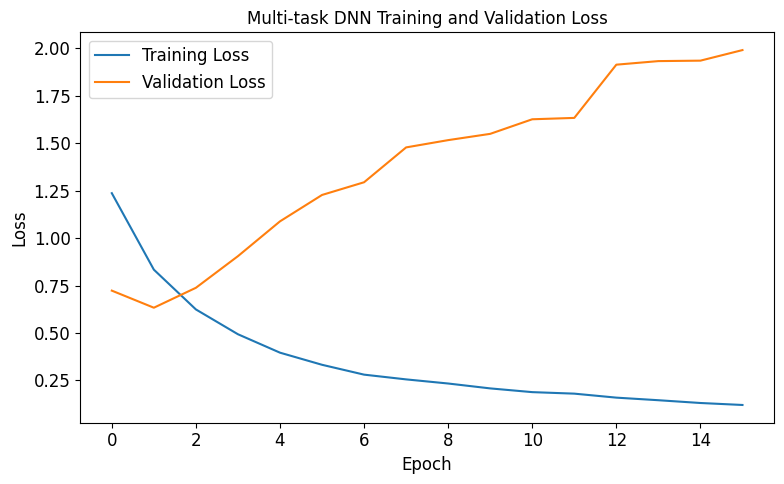

In [53]:
import matplotlib.pyplot as plt


# ============================================================
# TRAINING LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title(
    "Multi-task DNN Training and Validation Loss"
)

plt.legend()

plt.tight_layout()

plt.show()

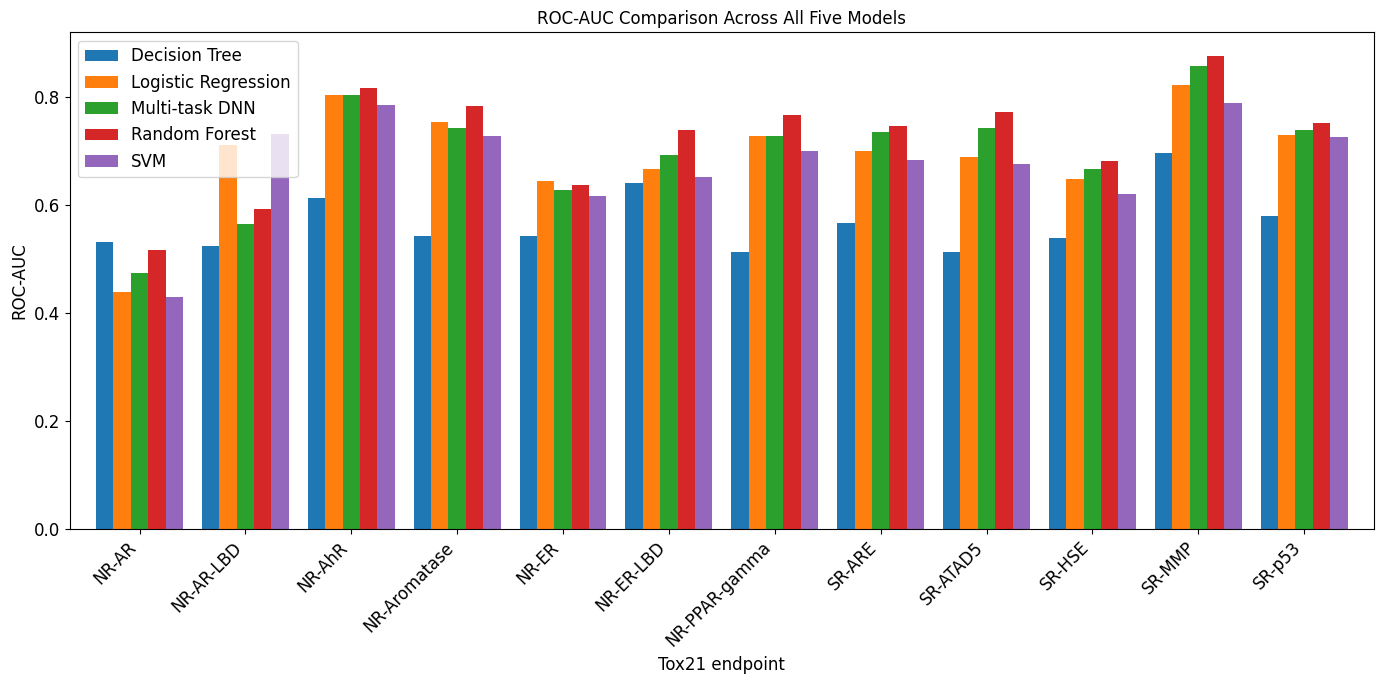

In [54]:
# ============================================================
# PLOT: ROC-AUC FOR ALL FIVE MODELS (TIMES NEW ROMAN, 12 PT)
# ============================================================

roc_pivot = all_model_results.pivot(
    index="Endpoint", columns="Model", values="ROC_AUC"
)
ax = roc_pivot.plot(kind="bar", figsize=(14, 7), width=0.82)
ax.set_xlabel("Tox21 endpoint", fontname="Times New Roman", fontsize=12)
ax.set_ylabel("ROC-AUC", fontname="Times New Roman", fontsize=12)
ax.set_title("ROC-AUC Comparison Across All Five Models",
             fontname="Times New Roman", fontsize=12)
ax.tick_params(axis="both", labelsize=12)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontname("Times New Roman")
    label.set_fontsize(12)
legend = ax.legend(fontsize=12)
if legend:
    for label in legend.get_texts():
        label.set_fontname("Times New Roman")
        label.set_fontsize(12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("Tox21_All_Models_ROC_AUC.png", dpi=300, bbox_inches="tight")
plt.show()

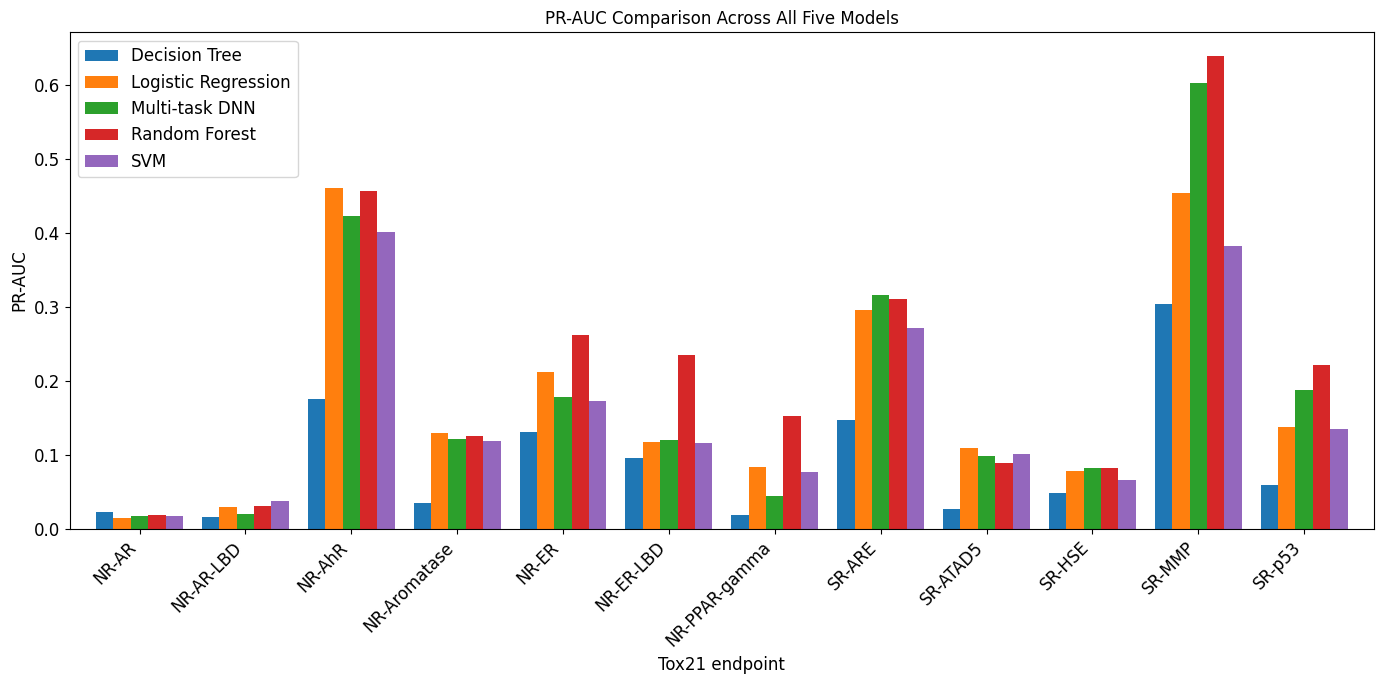

In [55]:
# ============================================================
# PLOT: PR-AUC FOR ALL FIVE MODELS (TIMES NEW ROMAN, 12 PT)
# ============================================================

pr_pivot = all_model_results.pivot(
    index="Endpoint", columns="Model", values="PR_AUC"
)
ax = pr_pivot.plot(kind="bar", figsize=(14, 7), width=0.82)
ax.set_xlabel("Tox21 endpoint", fontname="Times New Roman", fontsize=12)
ax.set_ylabel("PR-AUC", fontname="Times New Roman", fontsize=12)
ax.set_title("PR-AUC Comparison Across All Five Models",
             fontname="Times New Roman", fontsize=12)
ax.tick_params(axis="both", labelsize=12)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontname("Times New Roman")
    label.set_fontsize(12)
legend = ax.legend(fontsize=12)
if legend:
    for label in legend.get_texts():
        label.set_fontname("Times New Roman")
        label.set_fontsize(12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("Tox21_All_Models_PR_AUC.png", dpi=300, bbox_inches="tight")
plt.show()

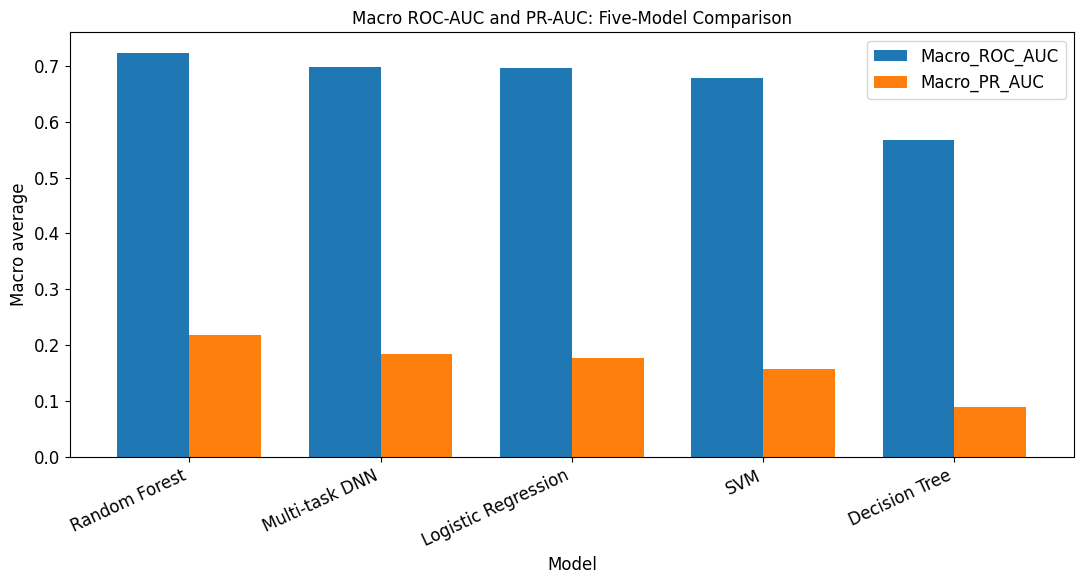

In [56]:
# ============================================================
# PLOT: MACRO ROC-AUC AND PR-AUC ACROSS ALL MODELS
# ============================================================

macro_plot = macro_summary.set_index("Model")[
    ["Macro_ROC_AUC", "Macro_PR_AUC"]
]
ax = macro_plot.plot(kind="bar", figsize=(11, 6), width=0.75)
ax.set_xlabel("Model", fontname="Times New Roman", fontsize=12)
ax.set_ylabel("Macro average", fontname="Times New Roman", fontsize=12)
ax.set_title("Macro ROC-AUC and PR-AUC: Five-Model Comparison",
             fontname="Times New Roman", fontsize=12)
ax.tick_params(axis="both", labelsize=12)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontname("Times New Roman")
    label.set_fontsize(12)
legend = ax.legend(fontsize=12)
if legend:
    for label in legend.get_texts():
        label.set_fontname("Times New Roman")
        label.set_fontsize(12)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig("Tox21_All_Models_Macro_Comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## Five-model comparison and formatting

This notebook compares:
1. Multi-task Deep Neural Network (DNN)
2. Random Forest (RF)
3. Linear Support Vector Machine (SVM)
4. Logistic Regression
5. Decision Tree

Each single-task baseline is trained separately for each of the 12 endpoints using only compounds with observed labels for that endpoint. All models use the same precomputed train/test split and molecular features. ROC-AUC and PR-AUC are reported because ordinary accuracy can be misleading for sparse, imbalanced toxicity labels.

All generated Matplotlib plots use **Times New Roman, 12 pt**. The comparison workbook is `Tox21_All_Model_Comparison.xlsx`.

**Interpretation caution:** SVM scores use the decision function rather than calibrated probabilities; this is appropriate for ranking-based ROC-AUC and average precision. Results should be interpreted from the actual run and not assumed in advance.

NameError: name 're' is not defined

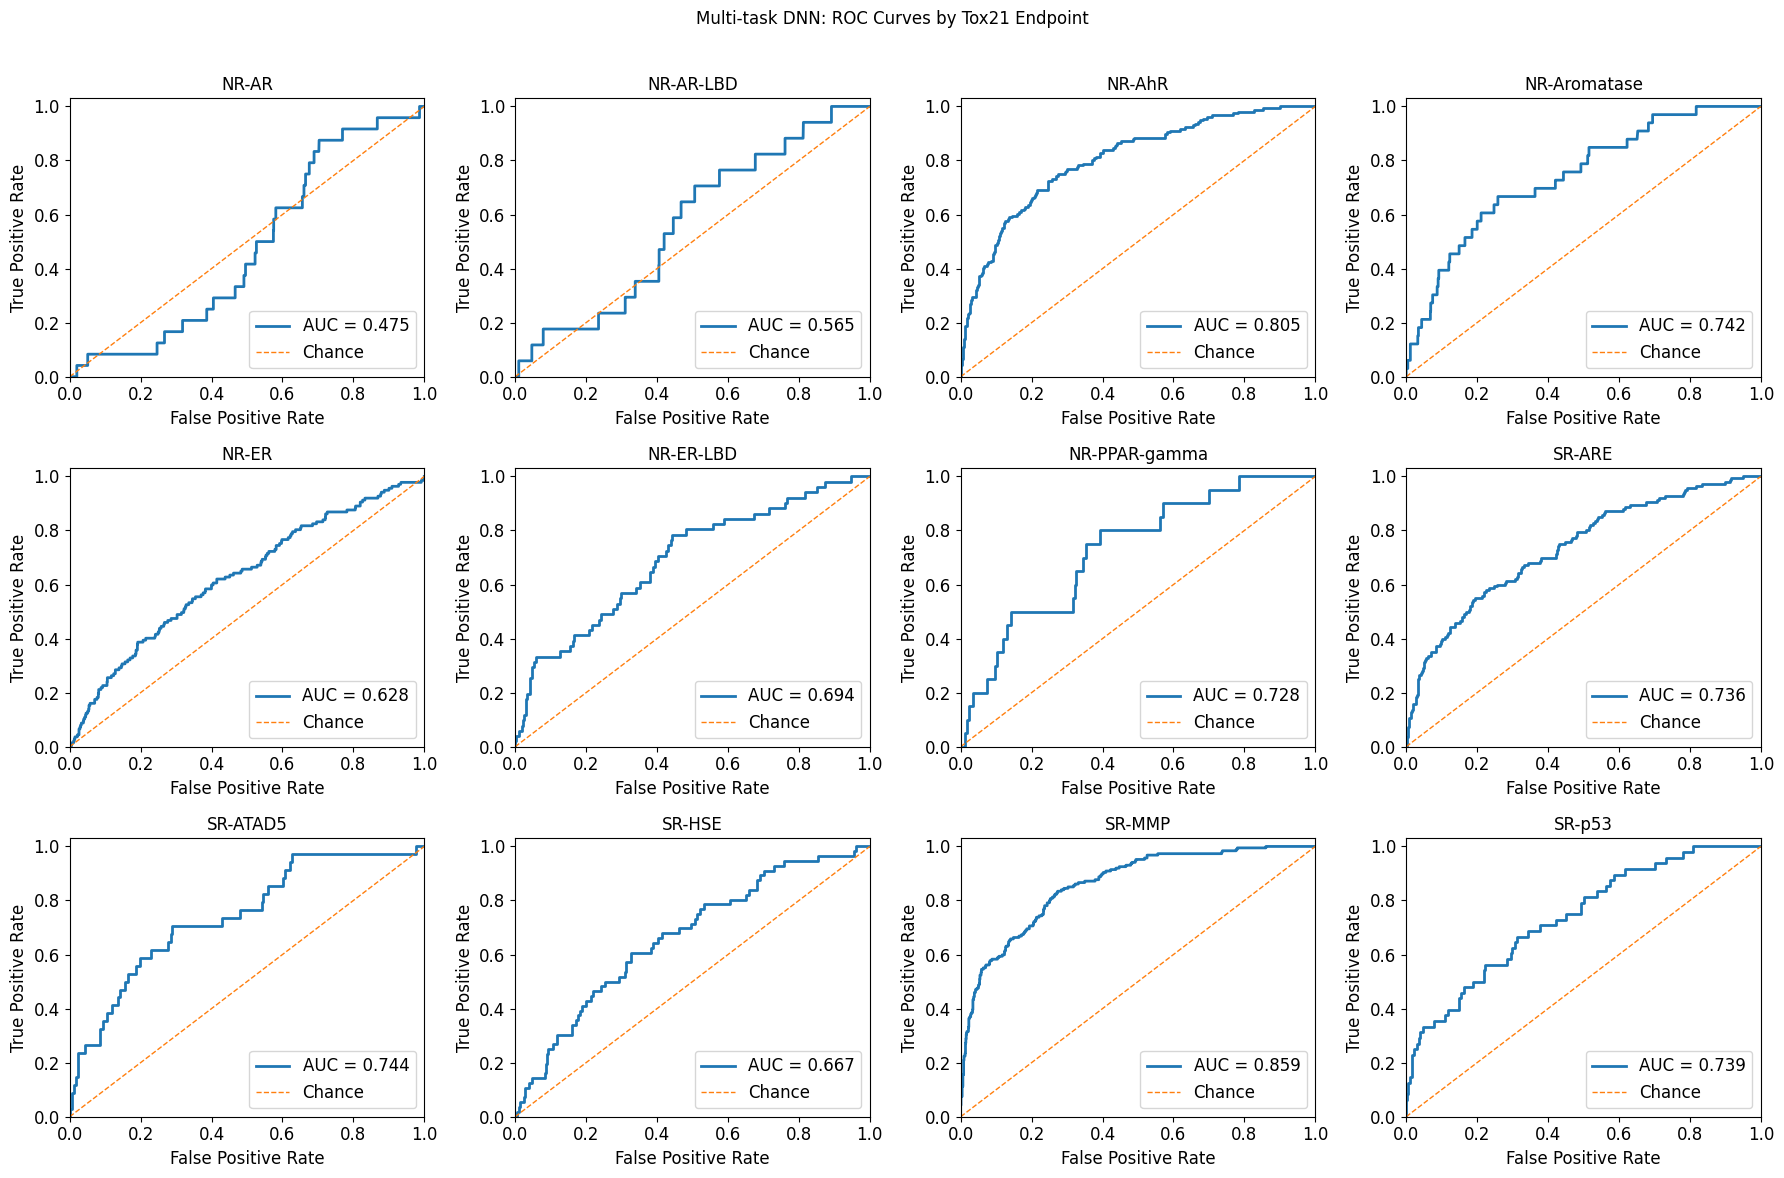

In [57]:
# ============================================================
# MODEL-SPECIFIC ROC AND PRECISION-RECALL CURVES
# Each model gets its own 12-endpoint panel for ROC and PR.
# Typography: Times New Roman, 12 pt.
# ============================================================

import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.metrics import roc_curve, precision_recall_curve, auc, average_precision_score

mpl.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 12,
    "axes.titlesize": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 12,
})

# Assemble consistent held-out predictions for all five models.
# Values are stored as (true labels, continuous model scores).
dnn_predictions = {}
for i, endpoint in enumerate(TARGETS):
    observed = (M_test[:, i] == 1)
    dnn_predictions[endpoint] = (
        np.asarray(Y_test[observed, i]).astype(int),
        np.asarray(test_predictions[observed, i], dtype=float).reshape(-1)
    )

# Random Forest scores are saved in rf_predictions by the RF training cell.
# Additional models save their scores in additional_predictions.
model_prediction_sets = {
    "Multi-task DNN": dnn_predictions,
    "Random Forest": rf_predictions,
}
for model_name in ["SVM", "Logistic Regression", "Decision Tree"]:
    model_prediction_sets[model_name] = additional_predictions.get(model_name, {})

# Save per-endpoint curve summary data for reproducibility.
curve_summary_rows = []

def plot_model_curves(model_name, predictions_by_endpoint, curve_type="roc"):
    fig, axes = plt.subplots(3, 4, figsize=(18, 12))
    axes = axes.ravel()

    for i, endpoint in enumerate(TARGETS):
        ax = axes[i]
        pair = predictions_by_endpoint.get(endpoint)

        if pair is None:
            ax.text(0.5, 0.5, "No predictions available",
                    ha="center", va="center",
                    fontname="Times New Roman", fontsize=12)
            ax.set_title(str(endpoint), fontname="Times New Roman", fontsize=12)
            ax.axis("off")
            continue

        y_true, scores = pair
        y_true = np.asarray(y_true).astype(int).ravel()
        scores = np.asarray(scores, dtype=float).ravel()

        valid = np.isfinite(scores)
        y_true = y_true[valid]
        scores = scores[valid]

        if len(y_true) == 0 or len(np.unique(y_true)) < 2:
            ax.text(0.5, 0.5, "ROC/curve undefined\n(single class or no data)",
                    ha="center", va="center",
                    fontname="Times New Roman", fontsize=12)
            ax.set_title(str(endpoint), fontname="Times New Roman", fontsize=12)
            ax.set_xlabel("False Positive Rate" if curve_type == "roc" else "Recall",
                          fontname="Times New Roman", fontsize=12)
            ax.set_ylabel("True Positive Rate" if curve_type == "roc" else "Precision",
                          fontname="Times New Roman", fontsize=12)
            continue

        if curve_type == "roc":
            x_vals, y_vals, _ = roc_curve(y_true, scores)
            score_value = auc(x_vals, y_vals)
            ax.plot(x_vals, y_vals, label=f"AUC = {score_value:.3f}", linewidth=2)
            ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="Chance")
            ax.set_xlabel("False Positive Rate", fontname="Times New Roman", fontsize=12)
            ax.set_ylabel("True Positive Rate", fontname="Times New Roman", fontsize=12)
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1.03)
            metric_name = "ROC_AUC"
        else:
            precision, recall, _ = precision_recall_curve(y_true, scores)
            score_value = average_precision_score(y_true, scores)
            ax.plot(recall, precision, label=f"Average precision = {score_value:.3f}", linewidth=2)
            baseline = np.mean(y_true == 1)
            ax.axhline(baseline, linestyle="--", linewidth=1, label=f"Prevalence = {baseline:.3f}")
            ax.set_xlabel("Recall", fontname="Times New Roman", fontsize=12)
            ax.set_ylabel("Precision", fontname="Times New Roman", fontsize=12)
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1.03)
            metric_name = "Average_Precision"

        ax.set_title(str(endpoint), fontname="Times New Roman", fontsize=12)
        ax.tick_params(axis="both", labelsize=12)
        legend = ax.legend(loc="lower right" if curve_type == "roc" else "lower left",
                           fontsize=12, frameon=True)
        if legend:
            for label in legend.get_texts():
                label.set_fontname("Times New Roman")
        curve_summary_rows.append({
            "Model": model_name,
            "Endpoint": endpoint,
            "Curve_Type": curve_type.upper(),
            "Metric": metric_name,
            "Score": float(score_value)
        })

    fig.suptitle(
        f"{model_name}: {'ROC Curves' if curve_type == 'roc' else 'Precision–Recall Curves'} by Tox21 Endpoint",
        fontname="Times New Roman", fontsize=12
    )
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    safe_name = re.sub(r"[^A-Za-z0-9]+", "_", model_name).strip("_")
    suffix = "ROC_Curves" if curve_type == "roc" else "PR_Curves"
    fig.savefig(f"{safe_name}_{suffix}.png", dpi=300, bbox_inches="tight")
    plt.show()

# One ROC figure and one PR figure for every model.
for model_name, predictions_by_endpoint in model_prediction_sets.items():
    plot_model_curves(model_name, predictions_by_endpoint, curve_type="roc")
    plot_model_curves(model_name, predictions_by_endpoint, curve_type="pr")

curve_summary_df = pd.DataFrame(curve_summary_rows).drop_duplicates(
    subset=["Model", "Endpoint", "Curve_Type"], keep="last"
)
curve_summary_df.to_csv("Tox21_Model_Curve_Summary.csv", index=False)

print("Saved model-specific ROC and PR curve figures (300 dpi).")
print("Saved curve summary: Tox21_Model_Curve_Summary.csv")

In [58]:
# ============================================================
# OPTIONAL: PACKAGE ALL VISUALIZATIONS AND RESULT FILES
# Run after all model and visualization cells finish.
# ============================================================

import os
import zipfile
from google.colab import files

files_to_package = [
    name for name in os.listdir(".")
    if (
        name.endswith(".png")
        or name.endswith(".xlsx")
        or name.endswith(".csv")
    ) and (
        name.startswith("Tox21_")
        or name.endswith("_ROC_Curves.png")
        or name.endswith("_PR_Curves.png")
        or name in {
            "multitask_results.csv",
            "random_forest_results.csv",
            "additional_model_results.csv",
            "label_audit.csv"
        }
    )
]

zip_name = "Tox21_All_Model_Visualizations_and_Results.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zf:
    for filename in sorted(set(files_to_package)):
        zf.write(filename)

print("Files included in archive:")
for filename in sorted(set(files_to_package)):
    print(" -", filename)

files.download(zip_name)

Files included in archive:
 - Tox21_All_Model_Comparison.xlsx
 - Tox21_All_Model_Endpoint_Comparison.csv
 - Tox21_All_Model_Macro_Summary.csv
 - Tox21_All_Model_Winners_By_Endpoint.csv
 - Tox21_All_Models_Macro_Comparison.png
 - Tox21_All_Models_PR_AUC.png
 - Tox21_All_Models_ROC_AUC.png
 - additional_model_results.csv
 - label_audit.csv
 - multitask_results.csv
 - random_forest_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install -q lightgbm

# PART B — Improved pipeline (fair split + richer features + tuned models + ensemble)

**Why Part B exists.** In Part A the greedy scaffold split put all 1,698 acyclic molecules in *validation* and all 1,454 benzene-only molecules in *test*. The test set was therefore one scaffold group with a very different active rate (NR-AR ≈ 1.8 % vs 6 % in train), which capped every model near 0.70 regardless of quality.
Part B (i) replaces that split with a stratified *balanced* scaffold split, (ii) uses richer features, (iii) tempers class weights, (iv) adds tuned baselines and a rank-average ensemble, and (v) reports bootstrap confidence intervals.
Part B is self-contained: it re-reads the CSV and does not depend on variables from Part A except the Times-New-Roman plot style set in cell 2. Run it after `!pip install -q lightgbm`.

**Success criterion used here:** the *best* model's macro ROC-AUC ≥ 0.75. Endpoints below 0.65 are listed for information only.

In [ ]:
import os, random, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, MACCSkeys, rdFingerprintGenerator as rfg
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.preprocessing import QuantileTransformer
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from scipy.stats import rankdata
import lightgbm as lgb
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
RDLogger.DisableLog("rdApp.*"); warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

B_CSV = "/content/tox21_cleaned_final.csv" if os.path.exists("/content/tox21_cleaned_final.csv") else os.environ.get("TOX21_CSV", "tox21_cleaned_final.csv")
B_SMILES = "canonical_smiles"
B_TARGETS = ["NR-AR","NR-AR-LBD","NR-AhR","NR-Aromatase","NR-ER","NR-ER-LBD",
             "NR-PPAR-gamma","SR-ARE","SR-ATAD5","SR-HSE","SR-MMP","SR-p53"]
K = len(B_TARGETS)
B_TRAIN, B_VAL, B_TEST = 0.70, 0.15, 0.15
N_DNN_SEEDS = int(os.environ.get("N_DNN_SEEDS", 5))       # more seeds = steadier DNN, slower run
N_TREES = int(os.environ.get("N_TREES", 500))
N_BOOT = int(os.environ.get("N_BOOT", 1000))
print("TensorFlow", tf.__version__, "| CSV:", B_CSV)

## B1. Load, de-duplicate (InChIKey) and label audit

In [ ]:
dfb = pd.read_csv(B_CSV)
dfb = dfb[dfb[B_SMILES].apply(lambda s: isinstance(s, str) and Chem.MolFromSmiles(s) is not None)].copy()
n0 = len(dfb)
# replicate rows of one compound: an 'active' call wins; a missing label stays missing
dfb = dfb.groupby("inchikey", sort=False, as_index=False).agg(
    {B_SMILES: "first", **{t: "max" for t in B_TARGETS}}).reset_index(drop=True)
print(f"{n0} rows -> {len(dfb)} unique compounds")
audit_b = pd.DataFrame({"Tested": [int(dfb[t].notna().sum()) for t in B_TARGETS],
                        "Active": [int((dfb[t] == 1).sum()) for t in B_TARGETS]}, index=B_TARGETS)
audit_b["Missing_frac"] = 1 - audit_b.Tested / len(dfb)
audit_b["Active_rate"] = audit_b.Active / audit_b.Tested
print(audit_b.round(4))

## B2. Stratified *balanced* scaffold split
* scaffold groups with more than 30 molecules (acyclic, benzene, pyridine …) always go to **train**;
* the remaining small groups are shuffled and dealt into train/val/test;
* 2,000 random deals are drawn and the one whose per-endpoint active rates in val and test are closest to the global rate is kept (**labels only — model scores are never used**);
* hard checks: no scaffold overlap, and no single scaffold may exceed 5 % of val or test.

*Compromise to document:* whole scaffolds cannot be split, so exact 70/15/15 sizes and identical active rates for all 12 endpoints cannot both hold. Because the giant groups sit in train, train has a slightly lower active rate than val/test.

In [ ]:
dfb["scaffold"] = dfb[B_SMILES].apply(lambda s: Chem.MolToSmiles(MurckoScaffold.GetScaffoldForMol(Chem.MolFromSmiles(s))))
Yraw = dfb[B_TARGETS].to_numpy(dtype=float)
sid, snames = pd.factorize(dfb["scaffold"]); nsc = len(snames)
sc_n = np.bincount(sid, minlength=nsc).astype(float)
sc_t = np.zeros((nsc, K)); sc_a = np.zeros((nsc, K))
for k in range(K):
    ok = ~np.isnan(Yraw[:, k])
    sc_t[:, k] = np.bincount(sid[ok], minlength=nsc)
    sc_a[:, k] = np.bincount(sid[ok], weights=Yraw[ok, k], minlength=nsc)
glob_rate = sc_a.sum(0) / sc_t.sum(0)
Nb = len(dfb); n_tr, n_va = B_TRAIN * Nb, B_VAL * Nb
GIANT_MIN = 30
giant = np.where(sc_n > GIANT_MIN)[0]; small = np.where(sc_n <= GIANT_MIN)[0]

def draw_split(rng):
    lab = np.full(nsc, 2); lab[giant] = 0
    tr = sc_n[giant].sum(); va = 0.0
    for s in rng.permutation(small):
        if tr + sc_n[s] <= n_tr: lab[s] = 0; tr += sc_n[s]
        elif va + sc_n[s] <= n_va: lab[s] = 1; va += sc_n[s]
    return lab

def split_cost(lab):
    cost = 0.0
    for part, frac in ((1, B_VAL), (2, B_TEST)):
        m = lab == part; t = sc_t[m].sum(0); a = sc_a[m].sum(0)
        if (a < 15).any(): cost += 5.0
        cost += np.mean(np.abs(a / np.maximum(t, 1) - glob_rate) / glob_rate) + 3 * abs(sc_n[m].sum() / Nb - frac)
    return cost

rng = np.random.default_rng(SEED); best_lab, best_cost = None, 1e9
for _ in range(2000):
    lab = draw_split(rng); c = split_cost(lab)
    if c < best_cost: best_lab, best_cost = lab, c
mol_lab = best_lab[sid]
idx = {"train": np.where(mol_lab == 0)[0], "val": np.where(mol_lab == 1)[0], "test": np.where(mol_lab == 2)[0]}

for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    assert not set(dfb.scaffold.iloc[idx[a]]) & set(dfb.scaffold.iloc[idx[b]]), "scaffold leakage"
for p in ("val", "test"):
    top = dfb.scaffold.iloc[idx[p]].value_counts(normalize=True).iloc[0]
    assert top < 0.05, f"{p} is dominated by one scaffold ({top:.1%})"
print({k: f"{len(v)} ({len(v)/Nb:.1%})" for k, v in idx.items()}, "| split cost", round(best_cost, 3))

bal = pd.DataFrame({"Global": glob_rate, **{p: [np.nanmean(Yraw[idx[p], k]) for k in range(K)] for p in idx}}, index=B_TARGETS)
bal["val_actives"] = [int(np.nansum(Yraw[idx["val"], k])) for k in range(K)]
bal["test_actives"] = [int(np.nansum(Yraw[idx["test"], k])) for k in range(K)]
print(bal.round(4)); bal.to_csv("Tox21_v2_split_balance.csv")

# ---- Figure: active-rate balance ----
x = np.arange(K); w = 0.2
fig, ax = plt.subplots(figsize=(14, 5.5))
for j, (c, lab_) in enumerate((("Global", "Whole dataset"), ("train", "Train"), ("val", "Validation"), ("test", "Test"))):
    ax.bar(x + (j - 1.5) * w, bal[c] * 100, w, label=lab_)
ax.set_xticks(x); ax.set_xticklabels(B_TARGETS, rotation=40, ha="right")
ax.set_ylabel("Active rate (%)"); ax.set_title("Active rate per endpoint in each split (balanced scaffold split)")
ax.legend(ncol=4); plt.tight_layout(); plt.savefig("Tox21_v2_fig1_split_balance.png", bbox_inches="tight"); plt.show()

## B3. Features: ECFP4 + FCFP4 + atom-pair counts, MACCS keys, all RDKit 2D descriptors

In [ ]:
mols_b = [Chem.MolFromSmiles(s) for s in dfb[B_SMILES]]
g_e = rfg.GetMorganGenerator(radius=2, fpSize=2048)
g_f = rfg.GetMorganGenerator(radius=2, fpSize=1024, atomInvariantsGenerator=rfg.GetMorganFeatureAtomInvGen())
g_a = rfg.GetAtomPairGenerator(fpSize=1024)
def feats(m):
    d = []
    for _, f in Descriptors._descList:
        try: d.append(f(m))
        except Exception: d.append(0.0)
    return (g_e.GetCountFingerprintAsNumPy(m), g_f.GetCountFingerprintAsNumPy(m),
            g_a.GetCountFingerprintAsNumPy(m), np.array(list(MACCSkeys.GenMACCSKeys(m))), np.array(d))
t0 = time.time()
E, F, A, MK, D = [np.asarray(p, dtype=np.float64) for p in zip(*[feats(m) for m in mols_b])]
D = np.clip(np.nan_to_num(D, nan=0, posinf=0, neginf=0), -1e6, 1e6)
Xb = np.hstack([E, F, A, MK, D]).astype(np.float32)
n_fp = E.shape[1] + F.shape[1] + A.shape[1] + MK.shape[1]
keep = np.where((Xb[idx["train"]] != 0).sum(0) >= 10)[0]       # column filter uses TRAIN rows only
Xb = Xb[:, keep]; n_fp_kept = int((keep < n_fp).sum())
print(f"features built in {time.time()-t0:.0f}s -> {Xb.shape[1]} columns ({n_fp_kept} fingerprint, {Xb.shape[1]-n_fp_kept} descriptor)")

Xtr, Xva, Xte = (Xb[idx[p]] for p in ("train", "val", "test"))
Yfill = np.nan_to_num(Yraw); Mfull = (~np.isnan(Yraw)).astype(np.float32)
Ytr, Yva, Yte = (Yfill[idx[p]].astype(np.float32) for p in ("train", "val", "test"))
Mtr, Mva, Mte = (Mfull[idx[p]] for p in ("train", "val", "test"))

qt = QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=SEED)
def dnn_in(X, fit=False):
    de = qt.fit_transform(X[:, n_fp_kept:]) if fit else qt.transform(X[:, n_fp_kept:])
    return np.hstack([np.log1p(X[:, :n_fp_kept]), np.clip(de, -4, 4)]).astype(np.float32)
Dtr = dnn_in(Xtr, True); Dva = dnn_in(Xva); Dte = dnn_in(Xte)

## B4. √-tempered class weights, masked loss and unit tests
Full neg/pos weights (up to 27×) destabilise rare endpoints; the square root keeps them up-weighted but stable. Missing labels are never imputed (mask = 0).

In [ ]:
pos_w = np.array([np.sqrt((Ytr[Mtr[:, k] == 1, k] == 0).sum() / max((Ytr[Mtr[:, k] == 1, k] == 1).sum(), 1)) for k in range(K)], dtype=np.float32)
print("positive-class weights:", dict(zip(B_TARGETS, pos_w.round(2))))

def masked_bce(pw):
    w = tf.constant(pw, tf.float32)
    def loss(yc, p):
        y, m = yc[:, :K], yc[:, K:]
        p = tf.clip_by_value(p, 1e-7, 1 - 1e-7)
        l = -(y * tf.math.log(p) * w + (1 - y) * tf.math.log(1 - p))
        return tf.reduce_sum(l * m) / tf.maximum(tf.reduce_sum(m), 1.0)
    return loss

rs = np.random.RandomState(0)
yt = rs.randint(0, 2, (64, K)).astype(np.float32); mk = (rs.rand(64, K) > .3).astype(np.float32); pr_ = rs.rand(64, K).astype(np.float32)
Lf = masked_bce(pos_w); yt2 = yt.copy(); yt2[mk == 0] = rs.randint(0, 2, int((mk == 0).sum()))
assert np.isclose(Lf(np.hstack([yt, mk]), pr_).numpy(), Lf(np.hstack([yt2, mk]), pr_).numpy()), "masked labels leaked"
pv_ = tf.Variable(pr_)
with tf.GradientTape() as tp: v_ = Lf(tf.constant(np.hstack([yt, mk])), pv_)
g_ = tp.gradient(v_, pv_).numpy(); assert np.all(g_[mk == 0] == 0) and np.any(g_[mk == 1] != 0)
print("PASS: scrambling masked labels changes nothing, and the gradient at masked entries is exactly zero.")

## B5. Multi-task DNN (seed ensemble, early stopping on validation macro ROC-AUC)

In [ ]:
def macro(Y, M, P, pr=False):
    out = []
    for k in range(K):
        o = M[:, k] == 1
        if len(np.unique(Y[o, k])) < 2: continue
        out.append(average_precision_score(Y[o, k], P[o, k]) if pr else roc_auc_score(Y[o, k], P[o, k]))
    return float(np.mean(out))

class ValMacroAUC(keras.callbacks.Callback):
    def __init__(self, X, Y, M): super().__init__(); self.X, self.Y, self.M = X, Y, M
    def on_epoch_end(self, epoch, logs=None):
        logs["val_macro_roc_auc"] = macro(self.Y, self.M, self.model.predict(self.X, verbose=0, batch_size=1024))

def build_dnn(n_in):
    l2 = keras.regularizers.l2(1e-5); i = keras.Input((n_in,)); x = layers.Dropout(0.2)(i)
    for u, d in ((1024, .5), (512, .5), (256, .4)):
        x = layers.Dense(u, kernel_regularizer=l2)(x)
        x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x); x = layers.Dropout(d)(x)
    m = keras.Model(i, layers.Dense(K, activation="sigmoid")(x))
    m.compile(optimizer=keras.optimizers.Adam(5e-4), loss=masked_bce(pos_w)); return m

tr_t = np.hstack([Ytr, Mtr]); va_t = np.hstack([Yva, Mva]); dv, dt, hist = [], [], []
for s in range(N_DNN_SEEDS):
    keras.utils.set_random_seed(SEED + s); net = build_dnn(Dtr.shape[1])
    h = net.fit(Dtr, tr_t, validation_data=(Dva, va_t), epochs=80, batch_size=128, verbose=0, callbacks=[
        ValMacroAUC(Dva, Yva, Mva),
        keras.callbacks.EarlyStopping("val_macro_roc_auc", mode="max", patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau("val_macro_roc_auc", mode="max", factor=.5, patience=4, min_lr=1e-5)])
    hist.append(h.history)
    dv.append(net.predict(Dva, verbose=0)); dt.append(net.predict(Dte, verbose=0))
    print(f"seed {s}: val macro ROC-AUC {macro(Yva, Mva, dv[-1]):.4f} | test {macro(Yte, Mte, dt[-1]):.4f}")
P_dnn_va, P_dnn_te = np.mean(dv, 0), np.mean(dt, 0)
print(f"DNN ensemble: val {macro(Yva, Mva, P_dnn_va):.4f} | test {macro(Yte, Mte, P_dnn_te):.4f}")

## B6. Single-task baselines on the identical split (each trained only on compounds tested for that endpoint)

In [ ]:
def single_task(make, name, use_val=False):
    Pv = np.full(Yva.shape, np.nan); Pt = np.full(Yte.shape, np.nan)
    for k in range(K):
        a = Mtr[:, k] == 1; v = Mva[:, k] == 1; mdl = make(k)
        if use_val: mdl.fit(Xtr[a], Ytr[a, k], eval_set=[(Xva[v], Yva[v, k])], callbacks=[lgb.early_stopping(50, verbose=False)])
        else: mdl.fit(Xtr[a], Ytr[a, k])
        Pv[:, k] = mdl.predict_proba(Xva)[:, 1]; Pt[:, k] = mdl.predict_proba(Xte)[:, 1]
    print(f"{name:13s} val {macro(Yva, Mva, Pv):.4f} | test {macro(Yte, Mte, Pt):.4f}")
    return Pv, Pt

t0 = time.time()
P_rf_va, P_rf_te = single_task(lambda k: RandomForestClassifier(n_estimators=N_TREES, max_features="sqrt",
                    class_weight="balanced_subsample", n_jobs=-1, random_state=SEED), "RandomForest")
P_et_va, P_et_te = single_task(lambda k: ExtraTreesClassifier(n_estimators=N_TREES, max_features="sqrt",
                    class_weight="balanced_subsample", n_jobs=-1, random_state=SEED), "ExtraTrees")
def make_lgb(k):
    y = Ytr[Mtr[:, k] == 1, k]
    return lgb.LGBMClassifier(n_estimators=600, learning_rate=0.03, num_leaves=15, min_child_samples=10,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.3, reg_lambda=2.0,
        scale_pos_weight=float(np.sqrt((y == 0).sum() / max((y == 1).sum(), 1))), random_state=SEED, n_jobs=-1, verbose=-1)
P_lgb_va, P_lgb_te = single_task(make_lgb, "LightGBM", use_val=True)
print(f"baselines done in {time.time()-t0:.0f}s")

def rank_avg(ps):
    out = np.zeros_like(ps[0])
    for k in range(K): out[:, k] = np.mean([rankdata(p[:, k]) / len(p) for p in ps], 0)
    return out
P_ens_va = rank_avg([P_dnn_va, P_rf_va, P_et_va, P_lgb_va]); P_ens_te = rank_avg([P_dnn_te, P_rf_te, P_et_te, P_lgb_te])
print(f"Ensemble (equal-weight rank average): val {macro(Yva, Mva, P_ens_va):.4f} | test {macro(Yte, Mte, P_ens_te):.4f}")

## B7. Results: per-endpoint ROC-AUC / PR-AUC with bootstrap 95 % CIs, paired DNN-vs-RF test, success check

In [ ]:
models_te = {"Multi-task DNN": P_dnn_te, "Random Forest": P_rf_te, "ExtraTrees": P_et_te,
             "LightGBM": P_lgb_te, "Ensemble": P_ens_te}
rngb = np.random.default_rng(SEED)
def boot_idx(y):                       # stratified bootstrap: both classes always present
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    return [np.concatenate([rngb.choice(pos, len(pos)), rngb.choice(neg, len(neg))]) for _ in range(N_BOOT)]

rows = []
for k, t in enumerate(B_TARGETS):
    o = Mte[:, k] == 1; y = Yte[o, k]; bi = boot_idx(y)
    for name, P in models_te.items():
        s = P[o, k]
        br = np.array([roc_auc_score(y[i], s[i]) for i in bi]); bp = np.array([average_precision_score(y[i], s[i]) for i in bi])
        rows.append({"Model": name, "Endpoint": t, "Tested": int(o.sum()), "Active": int(y.sum()),
                     "ROC_AUC": roc_auc_score(y, s), "ROC_lo": np.percentile(br, 2.5), "ROC_hi": np.percentile(br, 97.5),
                     "PR_AUC": average_precision_score(y, s), "PR_lo": np.percentile(bp, 2.5), "PR_hi": np.percentile(bp, 97.5)})
res = pd.DataFrame(rows); res.to_csv("Tox21_v2_results_with_CI.csv", index=False)
summary = res.groupby("Model").agg(Macro_ROC_AUC=("ROC_AUC", "mean"), Min_endpoint_ROC=("ROC_AUC", "min"),
                                   Macro_PR_AUC=("PR_AUC", "mean")).sort_values("Macro_ROC_AUC", ascending=False)
summary.to_csv("Tox21_v2_macro_summary.csv")
print("=" * 80); print("TEST-SET SUMMARY (macro over 12 endpoints)"); print("=" * 80); print(summary.round(4).to_string())
print("\nROC-AUC per endpoint"); print(res.pivot(index="Endpoint", columns="Model", values="ROC_AUC").loc[B_TARGETS].round(3).to_string())
print("\nPR-AUC per endpoint");  print(res.pivot(index="Endpoint", columns="Model", values="PR_AUC").loc[B_TARGETS].round(3).to_string())

pair = []
for k, t in enumerate(B_TARGETS):
    o = Mte[:, k] == 1; y = Yte[o, k]; a, b = P_dnn_te[o, k], P_rf_te[o, k]
    diff = np.array([roc_auc_score(y[i], a[i]) - roc_auc_score(y[i], b[i]) for i in boot_idx(y)])
    lo, hi = np.percentile(diff, [2.5, 97.5])
    pair.append({"Endpoint": t, "Delta": roc_auc_score(y, a) - roc_auc_score(y, b), "lo": lo, "hi": hi,
                 "Verdict": "DNN better" if lo > 0 else "RF better" if hi < 0 else "no clear difference"})
pair = pd.DataFrame(pair); pair.to_csv("Tox21_v2_DNN_vs_RF_paired.csv", index=False)
print("\nPaired comparison, Multi-task DNN minus Random Forest (ROC-AUC, bootstrap 95% CI)")
print(pair.round(3).to_string(index=False))

best_name = summary.index[0]; best_macro = summary.iloc[0].Macro_ROC_AUC; best_min = summary.iloc[0].Min_endpoint_ROC
print(f"\nBest model: {best_name} | macro ROC-AUC = {best_macro:.4f} | lowest endpoint = {best_min:.4f}")
print("TARGET MET (best macro ROC-AUC >= 0.75)" if best_macro >= 0.75 else "TARGET NOT MET - report honestly and see tuning notes")
print("Info only - endpoints below 0.65 for the best model:",
      res[(res.Model == best_name) & (res.ROC_AUC < 0.65)].Endpoint.tolist() or "none")

## B8. Updated visualisations

In [ ]:
colors = {"Multi-task DNN": "#1f77b4", "Random Forest": "#2ca02c", "ExtraTrees": "#9467bd", "LightGBM": "#ff7f0e", "Ensemble": "#d62728"}
names = list(models_te)

# ---- Fig 2: forest plots with CIs (ROC and PR) ----
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharey=True)
for ax, (m, lo, hi, ttl) in zip(axes, (("ROC_AUC", "ROC_lo", "ROC_hi", "ROC-AUC"), ("PR_AUC", "PR_lo", "PR_hi", "PR-AUC"))):
    for j, name in enumerate(names):
        d = res[res.Model == name].set_index("Endpoint").loc[B_TARGETS]
        yy = np.arange(K) + (j - 2) * 0.15
        ax.errorbar(d[m], yy, xerr=[d[m] - d[lo], d[hi] - d[m]], fmt="o", ms=4, lw=1, color=colors[name], label=name, capsize=2)
    ax.set_yticks(range(K)); ax.set_yticklabels(B_TARGETS); ax.grid(axis="x", alpha=.3)
    ax.set_xlabel(ttl + " (test, 95% bootstrap CI)"); ax.set_title(f"{ttl} per endpoint")
    if ttl == "ROC-AUC": ax.axvline(0.75, ls="--", c="k", lw=1); ax.axvline(0.65, ls=":", c="gray", lw=1)
axes[0].invert_yaxis()            # shared y-axis: invert once
axes[0].legend(loc="lower left", fontsize=9)
plt.tight_layout(); plt.savefig("Tox21_v2_fig2_per_endpoint_CI.png", bbox_inches="tight"); plt.show()

# ---- Fig 3: macro summary incl. reference to the old notebook ----
old = {"Old DNN (Part A split)": (0.6985, 0.1847), "Old RF (Part A split)": (0.7237, 0.2188)}
lab3 = list(summary.index) + list(old)
roc3 = list(summary.Macro_ROC_AUC) + [v[0] for v in old.values()]
pr3 = list(summary.Macro_PR_AUC) + [v[1] for v in old.values()]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, vals, ttl in ((axes[0], roc3, "Macro ROC-AUC"), (axes[1], pr3, "Macro PR-AUC")):
    bars = ax.bar(range(len(lab3)), vals, color=[colors.get(n, "#bbbbbb") for n in lab3])
    for b_, n in zip(bars, lab3):
        if n.startswith("Old"): b_.set_hatch("//")
    for i, v in enumerate(vals): ax.text(i, v + .005, f"{v:.3f}", ha="center", fontsize=10)
    ax.set_xticks(range(len(lab3))); ax.set_xticklabels(lab3, rotation=30, ha="right"); ax.set_title(ttl)
axes[0].axhline(0.75, ls="--", c="k", lw=1); axes[0].text(len(lab3) - .5, 0.755, "0.75 target", ha="right", fontsize=10)
axes[0].set_ylim(0.5, 1.0)
plt.suptitle("Hatched bars = Part A results on the old (single-scaffold) test set; not directly comparable", fontsize=10, y=0.02)
plt.tight_layout(); plt.savefig("Tox21_v2_fig3_macro_summary.png", bbox_inches="tight"); plt.show()

# ---- Fig 4: heatmap ----
hm = res.pivot(index="Endpoint", columns="Model", values="ROC_AUC").loc[B_TARGETS, names]
fig, ax = plt.subplots(figsize=(8, 7)); im = ax.imshow(hm.values, cmap="RdYlGn", vmin=0.5, vmax=0.95, aspect="auto")
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=30, ha="right"); ax.set_yticks(range(K)); ax.set_yticklabels(B_TARGETS)
for i in range(K):
    for j in range(len(names)): ax.text(j, i, f"{hm.values[i, j]:.2f}", ha="center", va="center", fontsize=10)
plt.colorbar(im, label="Test ROC-AUC"); ax.set_title("ROC-AUC heatmap: endpoint × model")
plt.tight_layout(); plt.savefig("Tox21_v2_fig4_heatmap.png", bbox_inches="tight"); plt.show()

# ---- Fig 5/6: ROC and PR curves of the best model, per endpoint ----
P_best = models_te[best_name]
for kind, fname in (("roc", "Tox21_v2_fig5_ROC_curves.png"), ("pr", "Tox21_v2_fig6_PR_curves.png")):
    fig, axes = plt.subplots(3, 4, figsize=(16, 11)); axes = axes.ravel()
    for k, t in enumerate(B_TARGETS):
        o = Mte[:, k] == 1; y = Yte[o, k]; s = P_best[o, k]; ax = axes[k]
        if kind == "roc":
            fpr, tpr, _ = roc_curve(y, s); ax.plot(fpr, tpr, lw=2); ax.plot([0, 1], [0, 1], "k--", lw=1)
            ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title(f"{t}  (AUC {roc_auc_score(y, s):.3f})")
        else:
            p_, r_, _ = precision_recall_curve(y, s); ax.plot(r_, p_, lw=2); ax.axhline(y.mean(), c="k", ls="--", lw=1)
            ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title(f"{t}  (AP {average_precision_score(y, s):.3f})")
        ax.grid(alpha=.3)
    plt.suptitle(f"{'ROC' if kind == 'roc' else 'Precision-recall'} curves — {best_name} (dashed = chance/baseline)", y=1.0)
    plt.tight_layout(); plt.savefig(fname, bbox_inches="tight"); plt.show()

# ---- Fig 7: paired DNN - RF ----
fig, ax = plt.subplots(figsize=(8, 6.5)); p_ = pair.iloc[::-1].reset_index(drop=True)
cc = ["#1f77b4" if v == "DNN better" else "#2ca02c" if v == "RF better" else "#888888" for v in p_.Verdict]
ax.barh(range(K), p_.Delta, color=cc, alpha=.8)
ax.errorbar(p_.Delta, range(K), xerr=[p_.Delta - p_.lo, p_.hi - p_.Delta], fmt="none", ecolor="k", capsize=3)
ax.axvline(0, c="k", lw=1); ax.set_yticks(range(K)); ax.set_yticklabels(p_.Endpoint)
ax.set_xlabel("ROC-AUC difference: Multi-task DNN − Random Forest (95% CI)")
ax.set_title("Where does multi-task sharing help?\nblue = DNN better, green = RF better, grey = no clear difference")
plt.tight_layout(); plt.savefig("Tox21_v2_fig7_DNN_vs_RF.png", bbox_inches="tight"); plt.show()

# ---- Fig 8: DNN learning curves ----
fig, ax = plt.subplots(figsize=(8, 5))
for i, h in enumerate(hist):
    ax.plot(h["val_macro_roc_auc"], alpha=.7, label=f"seed {i}")
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation macro ROC-AUC"); ax.set_title("DNN validation macro ROC-AUC (early-stopped)")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.savefig("Tox21_v2_fig8_dnn_training.png", bbox_inches="tight"); plt.show()

## B9. Package outputs (Colab)

In [ ]:
import glob, zipfile
outs = sorted(glob.glob("Tox21_v2_*.png") + glob.glob("Tox21_v2_*.csv"))
with zipfile.ZipFile("Tox21_v2_outputs.zip", "w") as z:
    for f in outs: z.write(f)
print("Saved:", outs)
try:
    from google.colab import files; files.download("Tox21_v2_outputs.zip")
except Exception: pass